<p class="lead">This is the last unit, and it has two jobs. The first is to make everything you have built <em>trustworthy</em>: a result that another person — or you, six months from now — can reproduce, and that is honest about what it does and does not predict. The second is to put the whole course to work. You will take a real drug target, pull its data from a public database, curate it, turn molecules into vectors, look at the chemical space, train and <em>honestly</em> validate a model, delimit where that model may be believed, propose a few new molecules, and write the result up as a model card. Nothing here is new chemistry or new machine learning; it is the discipline that separates a convincing demonstration from a result you can stand behind.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Set up a reproducible cheminformatics project — pinned environment, fixed seeds, versioned data — and justify each choice against the FAIR principles.</li>
<li>Recognise and reproduce the classic failure modes of molecular machine learning: overfitting, optimistic data splits and leakage, activity cliffs, chance correlation, and the wrong metric on imbalanced data.</li>
<li>Carry one target from raw public data to a validated, applicability-domain-aware model, with a chemical-space analysis and a small, honestly-filtered design exercise.</li>
<li>Document the result as a data sheet and a model card that state plainly what the model can and cannot be used for.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it once end to end; then re-run cells while changing one thing at a time — a seed, a split, a threshold — and watch the numbers move. Green <strong>chemistry boxes</strong> define each chemical term the first time it appears. This unit assumes the earlier ones: fingerprints come from Unit 5, standardisation from Unit 4, data acquisition from Unit 6, curation from Unit 7, chemical space from Unit 8, models from Units 12-13, honest validation and applicability domain from Unit 14, and the design ideas from Units 17-18. Where a method was derived earlier, we use it and point back rather than re-deriving it.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import sys, platform, hashlib, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, scipy
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, AllChem, Descriptors, DataStructs, Crippen
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize
rdkit.RDLogger.DisableLog("rdApp.*")        # silence RDKit valence/parse chatter in this teaching notebook
SEED = 0
np.random.seed(SEED)                         # one global seed; every estimator below also takes random_state=SEED
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("python %s | numpy %s | pandas %s | scikit-learn %s | scipy %s | rdkit %s"
      % (platform.python_version(), np.__version__, pd.__version__, sklearn.__version__, scipy.__version__, rdkit.__version__))

python 3.11.15 | numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | scipy 1.17.1 | rdkit 2026.03.4


## 1. What a credible cheminformatics result looks like

A cheminformatics project almost always ends in a single claim of the form "this model predicts property *P* with accuracy *A*". The entire value of the project rests on whether that claim is true — not true on the data you happened to have, but true on the molecules you will actually apply it to. The literature of the last decade is, to a large extent, a sustained warning that the headline accuracy is usually optimistic and the applicability usually narrower than advertised.<sup class="c"><a href="#r1">[1]</a></sup> Two influential reviews by Bender and Cortés-Ciriano catalogue how artificial-intelligence results in drug discovery become "real" or remain "illusions", and the difference is almost never the algorithm — it is the data, the split, the metric and the honesty of the reporting.<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>

<div class="box bridge"><h4>Chemistry box — assay, activity, IC50 and pIC50</h4>
<p>An <strong>assay</strong> is a laboratory experiment that measures how strongly a molecule acts on a biological target (say, an enzyme). The most common readout is the <strong>IC50</strong>: the concentration of the molecule that reduces the target's activity by half. A <em>smaller</em> IC50 means a <em>more</em> potent molecule. Because IC50 values span many orders of magnitude (nanomolar to millimolar), they are compressed to a logarithmic scale, <strong>pIC50</strong> = &minus;log<sub>10</sub>(IC50 in molar). On this scale a pIC50 of 9 (1 nM) is very potent, 5 (10 &micro;M) is weak, and a one-unit change is a tenfold change in concentration. "Potency" or "activity" throughout this unit means pIC50. A molecule's pIC50 is the number we will try to predict from its structure — a quantitative structure-activity relationship, or <strong>QSAR</strong> (Unit 12).</p></div>

The professional standard, distilled from best-practice papers for machine learning in chemistry,<sup class="c"><a href="#r4">[4]</a></sup> is: (i) the work can be re-run and gives the same numbers; (ii) the validation estimates performance on molecules genuinely unlike the training set, not near-duplicates of it; (iii) the model states where it may be trusted; and (iv) the report is specific about data provenance and limitations. The schematic below contrasts the number a careless pipeline reports with the number an honest one reports — the gap between them is the subject of this unit.

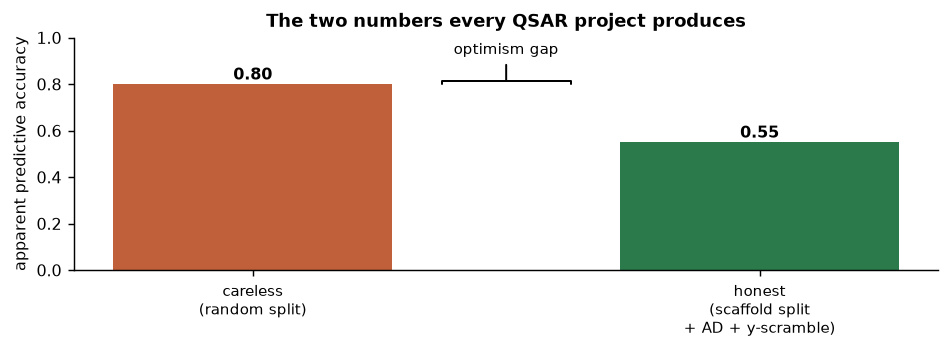

In [2]:
# A schematic (drawn, not imported) of the gap between the reported and the honest estimate.
fig, ax = plt.subplots(figsize=(7.4, 2.8))
stages = ["raw data", "careless\n(random split)", "honest\n(scaffold split\n+ AD + y-scramble)"]
vals = [None, 0.80, 0.55]
ax.bar([1, 2], [0.80, 0.55], color=["#c0603a", "#2b7a4b"], width=0.55)
ax.set_xticks([1, 2]); ax.set_xticklabels(stages[1:], fontsize=8.5)
ax.set_ylabel("apparent predictive accuracy"); ax.set_ylim(0, 1)
ax.annotate("optimism gap", xy=(1.5, 0.80), xytext=(1.5, 0.93), ha="center", fontsize=8.5,
            arrowprops=dict(arrowstyle="-[,widthB=4.2", lw=1.1))
ax.set_title("The two numbers every QSAR project produces")
for x, v in zip([1, 2], [0.80, 0.55]):
    ax.text(x, v + 0.02, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The same model, two numbers. The left bar is the accuracy a careless pipeline reports after a random train/test split; the right bar is what the model actually achieves on new chemistry once the split, the applicability domain and a chance-correlation control are handled honestly. The values shown are illustrative placeholders for the schematic; the real version of this gap is measured on live data in Section 5.6, where a random split and a scaffold split of the <em>same</em> model differ by a wide margin. The rest of the unit is, in effect, a method for reporting the right-hand bar.</p>

## 2. Reproducible environments, seeds and data versioning

Reproducibility is the property that a third party, given your code and data, obtains your numbers. It is not a courtesy; it is the precondition for the result meaning anything. In cheminformatics three things break it most often: the software changes under you, randomness is unseeded, and the data silently drifts.

**Pin the environment.** RDKit's aromaticity model, descriptor definitions and even fingerprint hashing can change between releases; scikit-learn changes default hyper-parameters between versions. A result is only defined relative to a version set, so the first duty of a reproducible notebook is to record one — which is why the setup cell above printed every library version. The Colab install line (`!pip install rdkit`) should ideally pin a version (`rdkit==2026.3.4`) for a result you intend to publish.

In [3]:
# Seeds make randomness reproducible: two runs with the same seed are bit-for-bit identical.
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
Xd, yd = make_regression(n_samples=200, n_features=20, noise=10.0, random_state=SEED)
a = RandomForestRegressor(n_estimators=50, random_state=SEED).fit(Xd, yd).predict(Xd[:5])
b = RandomForestRegressor(n_estimators=50, random_state=SEED).fit(Xd, yd).predict(Xd[:5])
c = RandomForestRegressor(n_estimators=50, random_state=1).fit(Xd, yd).predict(Xd[:5])
print("seed 0, run A :", np.round(a, 3))
print("seed 0, run B :", np.round(b, 3), "-> identical to A:", np.allclose(a, b))
print("seed 1, run C :", np.round(c, 3), "-> identical to A:", np.allclose(a, c))

seed 0, run A : [  53.706   31.63   -40.366   71.833 -110.949]
seed 0, run B : [  53.706   31.63   -40.366   71.833 -110.949] -> identical to A: True
seed 1, run C : [  30.908   34.959   -5.627   55.736 -118.54 ] -> identical to A: False


With the same seed the two forests are identical to the last decimal; with a different seed the third forest differs, because the bootstrap sampling and feature subsampling drew a different random sequence. The result therefore depends on the seed — which is exactly why we fix it, so that the <em>reported</em> run is reproducible. Left unseeded (`random_state=None`), a model's accuracy is a random variable, and quoting a single run of it is quoting one arbitrary draw. The honest response is either to fix the seed (for reproducibility) or to report the mean and spread over many seeds (for the true uncertainty). The next cell shows why the second matters: the test score of an unseeded model wanders.

test R^2: mean 0.520  std 0.067  min 0.330  max 0.633


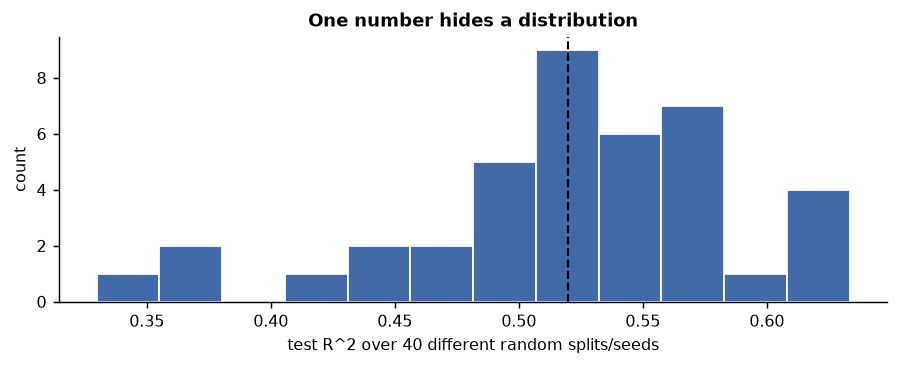

In [4]:
# Without a fixed seed the test score is a random variable; quote its spread, not one draw.
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
scores = []
for rep in range(40):
    Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.3, random_state=rep)   # different split each time
    m = RandomForestRegressor(n_estimators=60, random_state=rep).fit(Xtr, ytr)
    scores.append(r2_score(yte, m.predict(Xte)))
scores = np.array(scores)
fig, ax = plt.subplots(figsize=(7.0, 2.9))
ax.hist(scores, bins=12, color="#4269a8", edgecolor="white")
ax.axvline(scores.mean(), color="k", ls="--", lw=1.2)
ax.set_xlabel("test R^2 over 40 different random splits/seeds"); ax.set_ylabel("count")
ax.set_title("One number hides a distribution")
print("test R^2: mean %.3f  std %.3f  min %.3f  max %.3f" % (scores.mean(), scores.std(), scores.min(), scores.max()))
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> The test R&sup2; of the same model and data, over 40 different random splits and seeds. A single run could have landed anywhere in this histogram; the spread between its minimum and maximum is large relative to the differences people routinely claim between methods. The lesson is the one Section 5 applies throughout: report a mean and a spread (from cross-validation or repeated splits), fix a seed so the <em>reported</em> run is reproducible, and never compare two methods on single, differently-seeded runs.</p>

<div class="box warn"><h4>The seed is not the only source of irreproducibility</h4><p>Fixing <code>random_state</code> handles pseudo-random draws, but order-dependent operations (parallel reductions, hash-based sets, dictionary iteration before Python 3.7) and library-version changes can still move results. Record versions, avoid relying on set/dict ordering for anything numeric, and prefer deterministic algorithms where a choice exists. "It runs" is not "it reproduces".</p></div>

**Version the data.** The third silent failure is the dataset changing. Public databases are updated continually; the ChEMBL slice you download today is not the one you downloaded last year.<sup class="c"><a href="#r16">[16]</a></sup> The remedy is to freeze the exact rows you used and store a checksum, so that any later copy can be verified byte-for-byte. The cell below computes a content hash of a small frozen dataset — the same dataset the capstone uses — which is the minimal form of data versioning.

In [5]:
# Data versioning in one line: a content hash pins the exact rows used, so a result is defined.
demo_rows = [("CCO", 1.1), ("c1ccccc1", 2.1), ("CC(=O)Oc1ccccc1C(=O)O", 1.2)]
def dataset_fingerprint(rows):
    blob = json.dumps(sorted([(Chem.CanonSmiles(s), round(v, 4)) for s, v in rows])).encode()
    return hashlib.sha256(blob).hexdigest()
h1 = dataset_fingerprint(demo_rows)
h2 = dataset_fingerprint(demo_rows[::-1])                    # same rows, different order
h3 = dataset_fingerprint(demo_rows[:-1] + [("CC(=O)Oc1ccccc1C(=O)O", 1.3)])  # one value changed
print("fingerprint        :", h1[:16], "...")
print("reordered rows      :", h2[:16], "... -> same:", h1 == h2)
print("one value changed   :", h3[:16], "... -> same:", h1 == h3)

fingerprint        : c7ef62fa09773144 ...
reordered rows      : c7ef62fa09773144 ... -> same: True
one value changed   : 79211af7b1fea3f2 ... -> same: False


The fingerprint is invariant to row order (we sort and reduce each molecule to its canonical SMILES<sup class="c"><a href="#r24">[24]</a></sup> first, so two spellings of the same molecule cannot change the hash) but changes the instant a single value is edited. Storing this hash next to a result lets anyone confirm they hold the same data; storing the frozen rows themselves — as this notebook does for its capstone — makes the result self-contained and reproducible without a live database call. This is the operational core of "versioned data".

## 3. FAIR data and provenance

Beyond your own reproducibility is the community standard for data that others can reuse: the **FAIR** principles — data should be Findable, Accessible, Interoperable and Reusable.<sup class="c"><a href="#r5">[5]</a></sup> They were written for scientific data generally, but each has a concrete cheminformatics reading:

- **Findable**: every molecule has a persistent, globally unique identifier. In chemistry that is the **InChIKey**, a fixed-length hash of the molecular structure (Unit 3), and the database accession (a ChEMBL or PubChem ID).<sup class="c"><a href="#r26">[26]</a></sup>
- **Accessible**: the data can be retrieved by that identifier over a standard protocol (the ChEMBL and PubChem REST APIs of Unit 6).
- **Interoperable**: molecules are stored in standard, software-independent formats (SMILES, InChI, SDF — Unit 3), not screenshots or bespoke encodings.
- **Reusable**: the data carries provenance and a licence — where it came from, how it was measured, and what you are allowed to do with it.

<div class="box bridge"><h4>Chemistry box — the InChIKey as a universal molecular identifier</h4>
<p>The <strong>InChI</strong> (International Chemical Identifier) is a canonical string computed from a molecular structure; the <strong>InChIKey</strong> is a 27-character hash of it (e.g. <code>BSYNRYMUTXBXSQ-UHFFFAOYSA-N</code> for aspirin). Two laboratories that draw the same molecule independently will compute the same InChIKey, so it is the natural primary key for merging chemical datasets — the cheminformatics equivalent of a content-addressed identifier. It is computed from structure alone, so it needs no central registry.</p></div>

In [6]:
# FAIR in practice: a structure-derived, order-independent identifier that merges datasets safely.
named = {"aspirin": "CC(=O)Oc1ccccc1C(=O)O", "aspirin (drawn differently)": "O=C(O)c1ccccc1OC(C)=O",
         "caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C", "ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1"}
rows = [(n, Chem.MolToInchiKey(Chem.MolFromSmiles(s)), s) for n, s in named.items()]
tab = pd.DataFrame(rows, columns=["name", "InChIKey", "input SMILES"]).set_index("name")
print(tab[["InChIKey"]].to_string())
print("\nthe two aspirin drawings share a key:",
      tab.loc["aspirin", "InChIKey"] == tab.loc["aspirin (drawn differently)", "InChIKey"])

                                                InChIKey
name                                                    
aspirin                      BSYNRYMUTXBXSQ-UHFFFAOYSA-N
aspirin (drawn differently)  BSYNRYMUTXBXSQ-UHFFFAOYSA-N
caffeine                     RYYVLZVUVIJVGH-UHFFFAOYSA-N
ibuprofen                    HEFNNWSXXWATRW-UHFFFAOYSA-N

the two aspirin drawings share a key: True


The two different SMILES for aspirin map to the identical InChIKey, which is exactly why it is a safe merge key: it depends on the molecule, not on how someone happened to write it. When you combine measurements from several sources (a recurring task in Unit 7's curation), joining on InChIKey rather than on raw SMILES prevents both false splits (the same molecule counted twice under two spellings) and false merges. Provenance — recording for each row which database, assay and version it came from — completes the "Reusable" requirement and is the first column we will keep in the capstone.

## 4. How to fool yourself with a QSAR model

Most bad cheminformatics results are not fraud; they are self-deception, and they recur in a small number of patterns. This section reproduces the five most common ones on tiny, fast datasets so you can recognise their signatures. Each is a way the <em>reported</em> number (Figure 1, left) ends up far above the <em>honest</em> one (Figure 1, right).

### 4.1 Overfitting: a perfect fit to the training set is not a result

A model with enough capacity can fit any training set exactly, including its noise. The fit to the data it has seen then tells you nothing about new data. This is the oldest trap in statistics and it is acute in cheminformatics because molecular feature vectors are high-dimensional (a fingerprint has thousands of bits) and datasets are small.<sup class="c"><a href="#r29">[29]</a></sup> The cell fits polynomials of rising degree to a handful of noisy points and tracks the error on the training points versus on held-out points.

degree 1: train 0.41 test 0.55 | best held-out at degree 4 (test 0.27) | degree 12: train 0.18 test 0.36


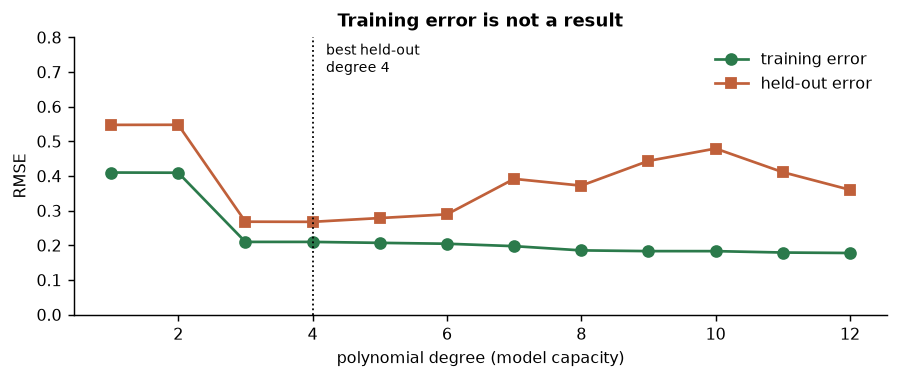

In [7]:
# Overfitting made visible: training error falls to zero while test error explodes.
rng = np.random.RandomState(SEED)
xt = np.sort(rng.rand(25)); yt = np.sin(2 * np.pi * xt) + rng.normal(0, 0.25, 25)
xv = np.sort(rng.rand(400)); yv = np.sin(2 * np.pi * xv) + rng.normal(0, 0.25, 400)
degrees = list(range(1, 13))
tr_err, te_err = [], []
for d in degrees:
    cf = np.polyfit(xt, yt, d)
    tr_err.append(np.sqrt(np.mean((np.polyval(cf, xt) - yt) ** 2)))
    te_err.append(np.sqrt(np.mean((np.polyval(cf, xv) - yv) ** 2)))
best = int(np.argmin(te_err)) + 1
fig, ax = plt.subplots(figsize=(7.0, 3.0))
ax.plot(degrees, tr_err, "o-", color="#2b7a4b", label="training error")
ax.plot(degrees, te_err, "s-", color="#c0603a", label="held-out error")
ax.axvline(best, color="k", ls=":", lw=1); ax.text(best + 0.2, 0.7, "best held-out\ndegree %d" % best, fontsize=8)
ax.set_xlabel("polynomial degree (model capacity)"); ax.set_ylabel("RMSE"); ax.set_ylim(0, 0.8)
ax.legend(frameon=False); ax.set_title("Training error is not a result")
print("degree 1: train %.2f test %.2f | best held-out at degree %d (test %.2f) | degree 12: train %.2f test %.2f"
      % (tr_err[0], te_err[0], best, min(te_err), tr_err[-1], te_err[-1]))
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> As polynomial degree (model capacity) rises, the training error falls steadily while the held-out error reaches a minimum at a moderate degree (marked), then turns and climbs. Past that minimum the model fits the training points ever more closely yet generalises worse and worse. The signature to recognise: a model that is far better on its training data than on held-out data is overfit, and its training-set score is not a result. In the capstone we never report a training-set score; we report cross-validated and scaffold-split scores only.</p>

### 4.2 Optimistic splits and leakage: the most expensive mistake in molecular ML

The single largest source of inflated accuracy is a train/test split that puts near-identical molecules on both sides. Chemical datasets are full of analogue series — many molecules sharing one scaffold (Unit 11) — so a random split almost always places close cousins of every test molecule into training. The model then succeeds by near-memorisation, and the reported accuracy does not transfer to genuinely new chemistry. Wallach and Heifets showed that many ligand-based benchmarks reward exactly this memorisation,<sup class="c"><a href="#r12">[12]</a></sup> and Sieg, Flachsenberg and Rarey traced how such hidden bias inflates reported performance.<sup class="c"><a href="#r13">[13]</a></sup> The honest alternatives split so that whole clusters — scaffolds (Unit 11) or time periods<sup class="c"><a href="#r9">[9]</a></sup> — are held out. The cell makes clustered data and compares a random split with a leave-cluster-out split.

random 5-fold CV   R^2 = 0.887  (neighbours leak across the split)
leave-cluster-out  R^2 = 0.438  (honest: no cluster seen in training)


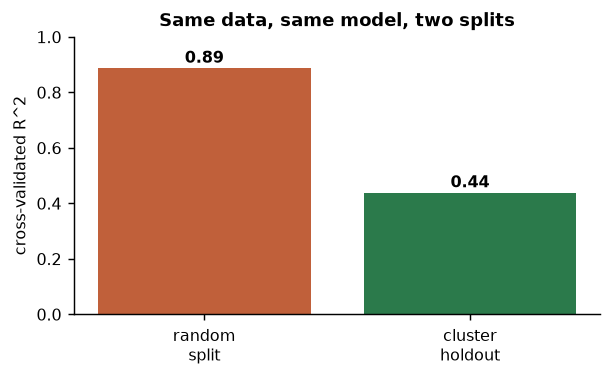

In [8]:
# Clustered data: a random split leaks neighbours across the split; a cluster-holdout does not.
from sklearn.datasets import make_blobs
from sklearn.model_selection import cross_val_predict, KFold, GroupKFold
from sklearn.ensemble import RandomForestRegressor
Xc, grp = make_blobs(n_samples=300, centers=15, n_features=8, cluster_std=2.0, random_state=SEED)
w = np.zeros(8); w[:3] = [1.0, 0.8, -0.6]
yc = Xc @ w + np.random.RandomState(SEED).normal(0, 1.0, 300)       # signal is in the FEATURES (generalisable)
rf = RandomForestRegressor(n_estimators=120, random_state=SEED, n_jobs=-1)
yp_rand = cross_val_predict(rf, Xc, yc, cv=KFold(5, shuffle=True, random_state=SEED))
yp_grp = cross_val_predict(rf, Xc, yc, cv=GroupKFold(5), groups=grp)                 # whole clusters held out
r2_rand = r2_score(yc, yp_rand); r2_grp = r2_score(yc, yp_grp)
print("random 5-fold CV   R^2 = %.3f  (neighbours leak across the split)" % r2_rand)
print("leave-cluster-out  R^2 = %.3f  (honest: no cluster seen in training)" % r2_grp)
fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.bar(["random\nsplit", "cluster\nholdout"], [r2_rand, r2_grp], color=["#c0603a", "#2b7a4b"])
ax.set_ylabel("cross-validated R^2"); ax.set_ylim(0, 1); ax.set_title("Same data, same model, two splits")
for i, v in enumerate([r2_rand, r2_grp]): ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> The identical model and data give a high cross-validated R&sup2; under a random split and a much lower one under a leave-cluster-out split, because the random split lets the model see near-neighbours of its test points. In real chemistry the clusters are scaffolds, and the gap is the "optimism gap" of Figure 1. The rule that follows is absolute for molecular data: <em>never report a random-split score as your generalisation estimate</em>; split by scaffold or by time and report that.</p>

### 4.3 Chance correlation: the y-randomization control

How do you know a model has learned real signal and not an accident of a high-dimensional feature space? Scramble the labels. If the targets are randomly permuted — destroying any true structure-activity relationship — an honest pipeline should produce near-zero predictive accuracy. If it still "predicts" the scrambled labels, the apparent skill is an artefact of the procedure (too many features, information leaking from the split, a flawed metric). This **y-randomization** (or y-scrambling) control is a standard and cheap safeguard.<sup class="c"><a href="#r30">[30]</a></sup><sup class="c"><a href="#r10">[10]</a></sup> The cell runs it on the clustered data from §4.2.

real R^2 0.438 | scrambled mean -0.109 max -0.031


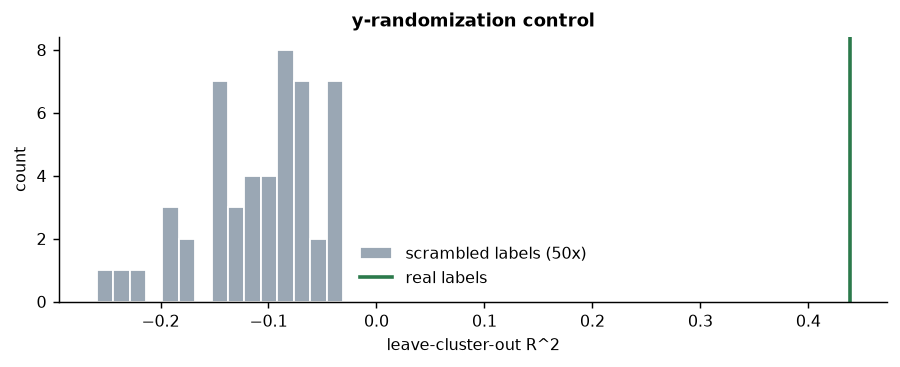

In [9]:
# y-randomization: scramble the labels many times; the real score must sit far above the scrambled ones.
real_r2 = r2_score(yc, cross_val_predict(rf, Xc, yc, cv=GroupKFold(5), groups=grp))
scr = []
rs = np.random.RandomState(SEED)
for _ in range(50):
    yperm = rs.permutation(yc)
    scr.append(r2_score(yperm, cross_val_predict(rf, Xc, yperm, cv=GroupKFold(5), groups=grp)))
scr = np.array(scr)
fig, ax = plt.subplots(figsize=(7.0, 2.9))
ax.hist(scr, bins=15, color="#9aa7b4", edgecolor="white", label="scrambled labels (50x)")
ax.axvline(real_r2, color="#2b7a4b", lw=2, label="real labels")
ax.set_xlabel("leave-cluster-out R^2"); ax.set_ylabel("count"); ax.legend(frameon=False)
ax.set_title("y-randomization control")
print("real R^2 %.3f | scrambled mean %.3f max %.3f" % (real_r2, scr.mean(), scr.max()))
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> The model's real leave-cluster-out R&sup2; (green line) sits far to the right of the distribution of scores obtained from 50 random label scrambles (grey), whose mean is near or below zero. That separation is the evidence that the model learned genuine signal rather than exploiting the dimensionality of the feature space. A real score that falls <em>inside</em> the scrambled distribution is a red flag — whatever the pipeline is doing, it is not learning the structure-activity relationship. We run this exact control on the capstone model in Section 5.</p>

### 4.4 Activity cliffs: where similarity-based reasoning breaks

Cheminformatics leans on the **similarity principle** (Unit 11): similar molecules tend to have similar properties. It is usually true, which is why fingerprint models work at all. But it fails at **activity cliffs** — pairs of molecules that are structurally almost identical yet differ sharply in activity.<sup class="c"><a href="#r20">[20]</a></sup> Cliffs are where the interesting medicinal chemistry lives and where models are least reliable, because a near-neighbour in feature space is a poor guide to activity exactly there. The cell shows a constructed cliff: two molecules differing by a single atom, with (hypothetical) activities an order of magnitude apart.

Tanimoto similarity of the pair: 0.69  (very similar)
but the activities differ by about 3 pIC50 units = ~1000-fold in concentration


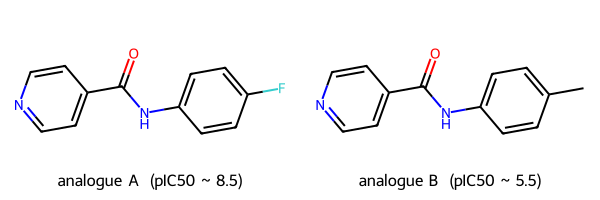

In [10]:
# An activity cliff: near-identical structures, very different activity -> high similarity is no guarantee.
pair = {"analogue A  (pIC50 ~ 8.5)": "O=C(Nc1ccc(F)cc1)c1ccncc1",
        "analogue B  (pIC50 ~ 5.5)": "O=C(Nc1ccc(C)cc1)c1ccncc1"}
mA, mB = [Chem.MolFromSmiles(s) for s in pair.values()]
gen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
tan = DataStructs.TanimotoSimilarity(gen.GetFingerprint(mA), gen.GetFingerprint(mB))
print("Tanimoto similarity of the pair: %.2f  (very similar)" % tan)
print("but the activities differ by about 3 pIC50 units = ~1000-fold in concentration")
Draw.MolsToGridImage([mA, mB], molsPerRow=2, subImgSize=(300, 200), legends=list(pair))

<p class="caption"><b>Figure 6.</b> An activity cliff: the two amides differ only by a single substituent (a fluorine versus a methyl on the aniline ring), giving a high Tanimoto similarity, yet their activities are taken to differ by roughly a thousandfold. A model that interpolates between near-neighbours will confidently predict them to be almost equally active and will be badly wrong for at least one. Cliffs are why a high average accuracy can hide large, systematic errors on the molecules a project most cares about, and why the applicability domain (Section 5) must be read together with, not instead of, the error bars.</p>

### 4.5 The wrong metric on imbalanced data

The last trap is reporting a metric that flatters the model. On an imbalanced classification task — say 10% actives — a model that predicts "inactive" for everything scores 90% accuracy while being useless. Accuracy is the wrong metric here; balanced accuracy, the Matthews correlation coefficient (MCC) and the area under the ROC curve are not fooled by the majority class.<sup class="c"><a href="#r10">[10]</a></sup> The cell demonstrates the trivial classifier.

In [11]:
# A do-nothing classifier can post a high accuracy on imbalanced data; honest metrics expose it.
from sklearn.metrics import accuracy_score, balanced_accuracy_score, matthews_corrcoef
y_true = np.array([0] * 90 + [1] * 10)          # 10% actives
y_allneg = np.zeros_like(y_true)                # predict 'inactive' for everyone
print("accuracy          : %.2f  <- looks good, means nothing" % accuracy_score(y_true, y_allneg))
print("balanced accuracy : %.2f  <- honest: no better than chance" % balanced_accuracy_score(y_true, y_allneg))
print("MCC               : %.2f  <- honest: zero correlation with truth" % matthews_corrcoef(y_true, y_allneg))

accuracy          : 0.90  <- looks good, means nothing
balanced accuracy : 0.50  <- honest: no better than chance
MCC               : 0.00  <- honest: zero correlation with truth


The do-nothing classifier scores 0.90 on accuracy but 0.50 on balanced accuracy and 0.00 on MCC — the honest metrics report that it has learned nothing. Choosing a metric that cannot be gamed by the class imbalance is part of honest reporting, and it is why the capstone uses ROC-AUC and MCC rather than raw accuracy. With the five traps named, we can run a project that avoids all of them.

<div class="box warn"><h4>These traps compound</h4><p>A single pipeline can commit several at once — a random split (4.2) feeding an overfit model (4.1) scored by accuracy on an imbalanced set (4.5), with no chance-correlation control (4.3) and no awareness of cliffs (4.4). Each inflates the headline number; together they can turn a model with no real skill into a publishable-looking result. The capstone's job is to do the opposite of each.</p></div>

## 5. The capstone: an end-to-end, honest project

We now carry one target through the whole pipeline. The target is **acetylcholinesterase (AChE)**, an enzyme whose inhibition is a treatment strategy for Alzheimer's disease; it is a well-studied target with abundant public data. The task: predict, from structure alone, whether a molecule is a potent AChE inhibitor. Every step reuses an earlier unit, and every choice is made to avoid the §4 traps.

<div class="box bridge"><h4>Chemistry box — target, inhibitor and the AChE task</h4>
<p>A <strong>target</strong> is the biological molecule (here an enzyme) whose activity a drug is meant to change. An <strong>inhibitor</strong> is a molecule that reduces the target's activity; its potency is the pIC50 defined in Section 1. AChE breaks down a signalling molecule in the brain, and inhibiting it raises that signal — the basis of several Alzheimer's drugs. Our data are measured AChE pIC50 values for a few hundred molecules, pulled from the ChEMBL database.</p></div>

### 5.1 Data acquisition (Unit 6) with a frozen, versioned snapshot

Following Section 2, the capstone does not depend on a live download: it carries a frozen, curated snapshot of AChE pIC50 data drawn from ChEMBL,<sup class="c"><a href="#r16">[16]</a></sup> so the notebook reproduces byte-for-byte offline. The cell below also shows — wrapped so it never blocks the build — how you would pull the same data live from the ChEMBL REST API (Unit 6) when running in Colab.

In [12]:
# Live fetch is attempted but never allowed to block; the frozen snapshot is what the capstone uses.
import urllib.request
def try_chembl(n=3, timeout=4):
    url = ("https://www.ebi.ac.uk/chembl/api/data/activity.json?"
           "target_chembl_id=CHEMBL220&standard_type=IC50&limit=%d" % n)
    try:
        with urllib.request.urlopen(url, timeout=timeout) as r:
            return len(json.load(r)["activities"])
    except Exception as e:
        return "unavailable (%s) - using frozen snapshot" % type(e).__name__
print("live ChEMBL probe:", try_chembl())

live ChEMBL probe: 3


In [13]:
# Frozen, versioned snapshot: 350 AChE inhibitors (canonical SMILES + median pIC50) curated from ChEMBL.
# Tagged hide-input so the HTML hides the 100+ data lines; the rows travel with the notebook for Colab.
_DATA = [
    ("O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1",7.00), ("CCN(C)Cc1ccc(CNCCN2CCNC2=C(C#N)C#N)o1",6.37), ("CCN(CC)Cc1ccc(CNCCN2CCNC2=C(C#N)C#N)o1",6.22),
    ("CCCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C",7.66), ("CN1CC[C@@]2(C)c3cc(OC(=O)NCCN4CCOCC4)ccc3N(C)[C@@H]12",6.16), ("N#CC(C#N)=C1NCCN1CCNCc1ccc(CN2CCCC2)o1",7.10),
    ("N#CC(C#N)=C1NCCN1CCNCc1ccc(CN2CCSCC2)o1",5.82), ("CC1CCCC(C)N1Cc1ccc(CNCCN2CCNC2=C(C#N)C#N)o1",5.35), ("C[n+]1ccn(COCCS(C)(=O)=O)c1/C=N/O",4.58),
    ("COc1cc2cc(C(=O)CCCCC3CC[N+](C)(Cc4ccccc4)CC3)sc2cc1OC",6.96), ("CCCn1c2c(c3c(Br)c(OC(=O)NC)ccc31)CC/C2=N/CC",6.64), ("COc1cc2cc(C(=O)CCC3CC[N+](C)(Cc4ccc([N+](=O)[O-])o4)CC3)sc2cc1OC",7.50),
    ("CNC(=O)Oc1ccc2c(c1)[C@@]1(C)CCN(Cc3ccccc3)C1N2Cc1ccccc1",5.45), ("Cc1cccc2nc3c(c(N)c12)CCCO3",6.82), ("CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN[C@@H]1N2C",7.66),
    ("CN(C)C(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C",6.68), ("CN1CCC(C2Cc3ccccc3C2=O)CC1",5.48), ("CC1CCN(Cc2ccccc2)CC1",8.28),
    ("CC1CCN(CC2Cc3ccccc3C2=O)CC1",6.32), ("Cc1cc(C)cc(NC(=O)Oc2ccc3c(c2)[C@]2(C)CCN(C)[C@@H]2N3C)c1",7.11), ("Cc1cccc(NC(=O)Oc2ccc3c(c2)[C@]2(C)CCN(C)[C@@H]2N3C)c1",7.55),
    ("CNC(=O)Oc1cccc(CN(C)CC#CCOc2ccc3c(=O)c4ccccc4oc3c2)c1",6.68), ("COc1ccc2c(c1)-c1nc3ccccc3c(N)c1C2",5.37), ("Nc1c2c(nc3ccccc13)-c1ccc(F)cc1C2",6.36),
    ("COc1ccc2c(N)c3c(nc2c1)CCCC3",6.46), ("COc1cccc2c1Cc1c-2nc2ccccc2c1N",5.78), ("Clc1ccc2c(NCc3ccccc3)c3c(nc2c1)CCCC3",6.77),
    ("CNC(=O)Oc1ccc2c(c1)[C@]1(C)CC[N@@+](C)([O-])[C@@H]1N2C",7.00), ("C#CCC(CCC)OC[n+]1ccn(C)c1/C=N/O",5.28), ("CCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)C1C2",7.11),
    ("CCCCCCNC(=O)Oc1ccc2c(c1)[C@@H]1CCN(CC)C1C2",6.68), ("COc1cc2c(cc1OC)C(=O)C(C)C2",7.35), ("CC(=O)Oc1cccc([N+](C)(C)C)c1",5.52),
    ("CCOc1cc2c(cc1OCC)C(=O)C(C)C2",7.31), ("CC(C)CCSC(=O)OCC[N+](C)(C)C",4.30), ("Cc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)C1N2C",7.99),
    ("CC(C)c1ccc(NC(=O)Oc2ccc3c(c2)[C@]2(C)CCN(C)C2N3Cc2ccccc2)cc1",4.89), ("CCCCCSC(=O)OCC[N+](C)(C)C",5.20), ("CC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3C(C1)C2",9.11),
    ("c1ccc2c(c1)CN1CCCC1=N2",5.43), ("CCCCCNc1cc(NCCSCc2ccc(CN(C)C)o2)c([N+](=O)[O-])cc1[N+](=O)[O-]",5.92), ("COc1ccc2cc(C(=O)CCC3CC[N+](C)(Cc4ccccc4)CC3)ccc2c1",7.30),
    ("CN(C)Cc1ccc(CSCCNc2cc(F)c([N+](=O)[O-])cc2[N+](=O)[O-])o1",6.92), ("CN(C)Cc1ccc(CSCCNc2cc(N)c([N+](=O)[O-])cc2[N+](=O)[O-])o1",7.08), ("COc1cc2cc(C(=O)CCC3CC[N+](C)(Cc4ccccc4)CC3)n(C)c2cc1OC",6.92),
    ("CCCNc1cc(NCCSCc2ccc(CN(C)C)o2)c([N+](=O)[O-])cc1[N+](=O)[O-]",6.58), ("CN(C)Cc1ccc(CSCCNc2cc(Nc3ncccc3[N+](=O)[O-])c([N+](=O)[O-])cc2[N+](=O)[O-])o1",6.19), ("Cc1nc2ccc(C(=O)CCC3CCN(Cc4ccccc4)CC3)cc2s1",8.17),
    ("CN(C)Cc1ccc(CSCCNc2cc(Nc3ccccc3C#N)c([N+](=O)[O-])cc2[N+](=O)[O-])o1",6.20), ("C[N+]1(Cc2ccccc2)CCC(CCC(=O)c2ccc3c(c2)OCCO3)CC1",7.00), ("C#CCN(C)C1CCc2ccc(OC(=O)N(C)C)cc21",4.89),
    ("C#CCN(C)[C@H](C)Cc1cccc(OC(=O)N(C)C2CCCCC2)c1",5.10), ("CCN(C)C(=O)Oc1cccc(CCN)c1",4.45), ("CN(C)C(=O)Oc1ccc2c(c1)C(N)CCC2",5.83),
    ("C#CCN(C)C(C)Cc1cccc(OC(=O)N(C)CCCCCC)c1",5.51), ("CCCN(C)C(=O)Oc1ccc2c(c1)C(N)CC2",5.14), ("C#CCN(C)CCc1cccc(OC(=O)N(C)CC)c1",4.78),
    ("C#CCN(C)[C@@H](C)Cc1cccc(OC(=O)N(C)CCCCCC)c1",5.47), ("CN(C)Cc1ccc(CSCCCCCCCSCc2ccc(CN(C)C)o2)o1",6.21), ("C/C=C(\C)C(=O)NC1=CC[C@@]2(C)[C@@H](CC[C@H]3C4CC[C@H]([C@H](C)N(C)C)[C@@]4(C)CC[C@@H]32)C1=O",4.86),
    ("C[C@@H]([C@H]1CC[C@H]2[C@@H]3CC[C@H]4C[C@@H](NC(=O)c5ccccc5)[C@@H](O)C[C@]4(C)[C@H]3CC[C@]12C)N(C)C",4.11), ("CN[C@H]1CC[C@@]2(C)C(CC[C@H]3[C@@H]4CC[C@H]([C@H](C)N(C)C)[C@@]4(C)CC[C@@H]32)C1",5.21), ("CN(C)Cc1ccc(CSCCSCc2ccc(CN(C)C)o2)o1",6.30),
    ("CC(=O)N(C)[C@H]1CC[C@@]2(C)[C@@H](CC[C@@H]3[C@@H]2CC[C@]2(C)[C@@H]([C@H](C)N(C)C)CC[C@@H]32)C1",4.15), ("CN(C)Cc1ccc(CSCC/N=C/NCCSCc2ccc(CN(C)C)o2)o1",5.52), ("CC[N+](C)(CC)CCC[n+]1c(-c2ccccc2)c2cc(N)ccc2c2ccc(N)cc21",4.49),
    ("COc1cc2onc(CCC3CCN(Cc4ccccc4)CC3)c2cc1C",8.24), ("COc1cc2cc(C(=O)C3CC[N+](C)(Cc4ccccc4)CCC3OC)sc2cc1OC",6.92), ("COc1cc2cc(C(=O)C3CCC[N+](C)(CCOc4ccccc4)CC3)sc2cc1OC",6.41),
    ("COc1cc2c(cc1OC)SC(CC1CC[N+](C)(Cc3ccccc3)CC1)C2",4.52), ("CNC(=O)Oc1cccc2c1OCC1CCN(C)C21",7.52), ("COc1ccc(CCN2CC(=O)N(CCc3ccccn3)CC2=O)cc1OC",4.70),
    ("Cc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CO[C@@H](C1)O2",7.01), ("COc1cc(C(=O)NNc2c3c(nc4ccccc24)CCCC3)cc(OC)c1OC",6.41), ("COc1cc(CCC(=O)NCCCCCC(=O)NNc2c3c(nc4ccccc24)CCCC3)cc(OC)c1OC",8.08),
    ("CN(CCCCCOc1ccc2c(=O)c3ccccc3oc2c1)Cc1ccccc1",5.16), ("CN(CCCCOc1ccc2c(=O)c3ccccc3oc2c1)Cc1ccccc1",5.20), ("COc1cc2cc(-c3ccc(CN(CCO)Cc4ccccc4)cc3)c(=O)oc2cc1OC",7.31),
    ("COc1ccc2cc(-c3cccc(CN(C)Cc4ccccc4)c3)c(=O)oc2c1",5.64), ("CCN(CCCCCCNC1=CC(=O)C(NCCCCCCN(CC)Cc2ccco2)=CC1=O)Cc1ccco1",6.84), ("CCCCC1=NC2(CCCC2)C(=O)N1CC(=O)c1ccc(Cl)cc1",6.54),
    ("CC(C)C1=N[C@H]2CC=C3CC4C(=O)C[C@]5(C)[C@@H]([C@H](C)N(C)C)[C@H](O)C[C@@]5(C)[C@@H]4CC[C@H]3[C@]2(C)CO1",6.52), ("C#CCN[C@@H]1CCc2cc(Cl)c(OC(=O)N(C)CCC)cc21",4.36), ("O=C(CO[N+](=O)[O-])NCCCNc1c2c(nc3ccccc13)CCCC2",7.55),
    ("O=[N+]([O-])OCCCCCCNCCCCNc1c2c(nc3ccccc13)CCCC2",7.74), ("O=C(CCO[N+](=O)[O-])NCCCCNc1c2c(nc3ccccc13)CCCC2",7.34), ("OCC1CCN(Cc2ccc(OCCCN3CCCCC3)cc2)CC1",5.96),
    ("CC(C)(O)[C@@H]1Cc2cc3ccc(=O)oc3cc2O1",4.17), ("C[C@@H]([C@H]1CC=C2[C@@H]3CCC4=C[C@@H](N(C)C)CC[C@]4(C)[C@H]3CC[C@@]21C)N(C)C",4.62), ("COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5ccccc35)CCCC4)CC1)C2",9.06),
    ("CC(=O)c1c(-c2ccc(OCCCCCCCN(C)Cc3ccccc3)cc2)oc2ccccc12",4.76), ("COc1ccc(C(=O)c2ccc(CN(CCN(C)C)Cc3ccccc3)cc2)cc1OC",5.06), ("Oc1cccc(C2=Nc3ccccc3SC(c3ccccc3F)C2)c1",4.15),
    ("Oc1cccc(C2=Nc3ccccc3SC(c3ccccc3)C2)c1",4.40), ("Oc1cccc(C2=Nc3ccccc3SC(c3cccc(O)c3)C2)c1",4.15), ("CC1=CC2Cc3nc4oc(C5CC5)nc4c(N)c3C(C1)C2",4.30),
    ("CC1=CC2Cc3nc4[nH]ncc4c(N)c3C(C1)C2",4.30), ("CC1=CC2Cc3nc4cc(Cl)ccc4c(Cl)c3C(C1)C2",4.65), ("CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCN=[N+]=[N-])c3C(C1)C2",8.06),
    ("CCN(CCCNC1=CC(=O)C(NCCCNC(=O)CCCCC2CCSS2)=CC1=O)Cc1ccccc1OC",6.72), ("C/C=C1\[C@H]2C=C(C)C[C@]1(/N=C/C=C/c1ccccc1)c1ccc(=O)[nH]c1C2",7.62), ("COc1ccc2c(c1)C(=O)/C(=C/c1ccc(CN(C)Cc3ccccc3)cc1)CC2",5.27),
    ("c1cc[n+](CCCCCCCCCC[n+]2ccccc2)cc1",6.40), ("COc1cccc2n1cc(-c1ccc(OC(=O)N(C)C)cc1)[n+]2C",5.09), ("Cc1cn2cc(C(N)=O)ccc2[n+]1C",4.57),
    ("O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CCCN2",7.23), ("O=C(CCC1CCN(Cc2ccc(F)cc2)CC1)c1ccc2c(c1)NCCCC2",6.41), ("CCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(CCC)[C@@H]1C2",7.21),
    ("CCCCCCCNC(=O)Oc1ccc2c(c1)C1CCN(CCC)C1C2",6.20), ("O=C(c1ccncc1)N(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1",7.19), ("CC(=O)N(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1",7.28),
    ("CCN(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1",4.92), ("O=C1c2ccc([N+](=O)[O-])cc2C(=O)N1CCC1CCN(Cc2ccccc2)CC1",7.90), ("O=C1c2ccc([N+](=O)[O-])cc2C(=O)N1CCC1CCN(Cc2ccc(Cl)cc2)CC1",6.62),
    ("Nc1ccc2c(c1)C(=O)N(CCC1CCN(Cc3ccccc3)CC1)C2=O",8.06), ("O=c1c2ccccc2ccn1CCC1CCN(Cc2ccccc2)CC1",5.96), ("O=c1[nH]c2ccccc2c(=O)n1CCC1CCN(Cc2ccccc2)CC1",8.38),
    ("Cc1cc(-c2ccc(Cl)cc2)nnc1NCCN1CCOCC1",4.47), ("CN(CCOCCNC(=S)NC(=O)c1ccccc1)Cc1ccccc1",6.92), ("COc1ccc(C(=O)NC(=S)NCCOCCN(C)Cc2ccccc2)cc1",7.58),
    ("CN(CCOCCNC(=S)NC(=O)c1cccc([N+](=O)[O-])c1)Cc1ccccc1",7.82), ("CN(CCOCCNC(=S)NC1CCCCC1)Cc1ccccc1",5.85), ("CN(C)CCCCCCCCCCCCNc1c2c(nc3ccccc13)CCCC2",6.58),
    ("Nc1c2c(nc3ccccc13)CCC2",7.25), ("O=C1c2ccccc2CCC1CC1CCN(c2ccccc2)CC1",5.68), ("Fc1ccc2c(NCCCCCCNc3c4c(nc5cc(F)ccc35)CCCC4)c3c(nc2c1)CCCC3",9.05),
    ("Fc1ccc2c(NCCCCCCCCNc3c4c(nc5cc(F)ccc35)CCCC4)c3c(nc2c1)CCCC3",9.15), ("c1ccc2c(NCCCCCCCCNc3c4c(nc5ccccc35)CCCCC4)c3c(nc2c1)CCCCC3",8.80), ("CNC(=O)Oc1cccc(CN(C)CCCCCCCOc2ccc3c(c2)O/C(=C\c2ccc4ccccc4c2)C3=O)c1",8.68),
    ("O=C(NCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2)c1c[nH]c2ccccc12",7.48), ("O=C(NCCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2)c1c[nH]c2ccccc12",7.44), ("O=C(Nc1cccc(C2=NCCN2)c1)Nc1cccc(C2=NCCN2)c1",6.23),
    ("Oc1c(CNCCCCCCCCCNc2c3c(nc4ccccc24)CCCC3)ccc2cccnc12",8.26), ("CN(C)c1cccc(OC(=O)Nc2ccccc2)c1",5.60), ("CNC(=O)Oc1ccc2c(c1)CC[C@@H]1CCN(C)[C@H]21",7.76),
    ("C[C@@]12CCN(Cc3ccccc3)[C@@H]1N(Cc1ccccc1)c1ccc(OC(=O)Nc3ccccc3)cc12",4.39), ("CNC(=O)Oc1ccc2c(c1)[C@@]1(C)CCN(C)[C@@H]1N2C",5.00), ("CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C=O",5.60),
    ("Cc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2",7.40), ("CCCCCNc1c2c(nc3ccc(OC)cc13)CCCC2",5.17), ("CCCCCCCNc1c2c(nc3ccc(OC)cc13)CCCC2",6.57),
    ("CCCCCCCCCCCCNc1c2c(nc3ccc(OC)cc13)CCCC2",6.00), ("COc1cc2c(cc1OC)C(=O)C1(C2)C(c2ccccc2Cl)CN(C)C12C(=O)Nc1ccccc12",5.37), ("COc1cc2c(cc1OC)C(=O)C1(C2)C(c2ccccc2Cl)CN(C)C12C(=O)Nc1ccc(Cl)cc12",5.18),
    ("COc1cc2c(cc1OC)C(=O)C1(C2)C(c2ccccc2)C(c2ccccc2)NC12C(=O)Nc1ccccc12",5.29), ("CC(C)(C)c1cc[n+](CCCCCCCCCC[n+]2ccc(C(C)(C)C)cc2)cc1",7.92), ("CC(C)(C)c1cc[n+](C/C=C\C[n+]2ccc(C(C)(C)C)cc2)cc1",5.70),
    ("CC(C)(C)c1cc[n+](CCCC[n+]2ccc(C(C)(C)C)cc2)cc1",5.43), ("O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CNCCO2",7.40), ("O=C(CCC1CCN(Cc2ccccc2)CC1)c1cc2c3c(c1)CC(=O)N3CCC2",8.44),
    ("O=C(CCC1CCN(Cc2cccc(Cl)c2)CC1)c1cc2c3c(ccn3C(=O)CC2)c1",8.31), ("COc1ccc(CN2CCC(CCC(=O)c3cc4c5c(ccn5C(=O)CC4)c3)CC2)cc1",6.46), ("C[N+](C)(CCNC(=O)C(=O)NCC[N+](C)(C)Cc1ccccc1Cl)Cc1ccccc1Cl",9.15),
    ("c1ccc2c[n+](CCCCCCCCCCC[n+]3ccc4ccccc4c3)ccc2c1",7.00), ("c1ccc2c(c1)ccc[n+]2CCCCCCCCC[n+]1cccc2ccccc21",7.10), ("Brc1ccc(CN2CCN(c3nccc(NCc4ccccc4)n3)CC2)cc1",4.59),
    ("Clc1ccc(CN2CCN(c3nccc(NCc4ccccc4)n3)CC2)cc1",4.70), ("COCCN1CCN(c2nccc(NCc3ccccc3)n2)CC1",4.57), ("CC1CCN(c2nccc(NCc3ccccc3)n2)CC1",4.74),
    ("c1ccc(CNc2ccnc(N3CCSCC3)n2)cc1",4.63), ("COc1cc2c(cc1OC)CN(c1cc[n+](Cc3ccc(C[n+]4ccc(N5CCCCC5)cc4)cc3)cc1)CC2",7.21), ("CN(Cc1ccccc1)Cc1ccc(C(=O)c2ccc(OCCCN3CCC(n4c(=O)[nH]c5ccccc54)CC3)cc2)cc1",7.17),
    ("CC(C)C1=N[C@H]2CC[C@]34C[C@]35C(=O)C[C@]3(C)[C@@H]([C@H](C)N(C)C)[C@H](O)C[C@@]3(C)[C@@H]5CC[C@H]4[C@]2(C)CC1",6.21), ("CC(C)C1=N[C@H]2CC[C@]34C[C@]35C(=O)C[C@]3(C)[C@@H]([C@H](C)N(C)C(=O)c6ccccc6)[C@H](O)C[C@@]3(C)[C@@H]5CC[C@H]4[C@]2(C)CS1",7.37), ("O=C(NCCNc1c2c(nc3ccccc13)CCCC2)c1ccc(F)cc1",9.09),
    ("CCCCC/C=C\C/C=C\CCCCCCCC(=O)OCCCc1ccc2oc(-c3ccc4c(c3)OCO4)cc2c1",5.57), ("CCCCCCCC/C=C\CCCCCCCC(=O)OCCCc1ccc2oc(-c3ccc4c(c3)OCO4)cc2c1",5.51), ("Oc1c(Cl)cc(Cl)c(Cl)c1Cc1c(O)c(Cl)cc(Cl)c1Cl",5.52),
    ("CC(C)OC(=O)C(C)(C)Oc1ccc(C(=O)c2ccc(Cl)cc2)cc1",4.81), ("CCCCCCCCCCCCCCCC[n+]1ccccc1",5.56), ("O=C(c1ccc(OCCN2CCCCC2)cc1)c1c(-c2ccc(O)cc2)sc2cc(O)ccc12",6.40),
    ("CC(CC(=O)C[C@@H](C)[C@H]1C[C@H](O)[C@@]2(C)C3=C(C(=O)C[C@]12C)[C@@]1(C)CCC(=O)C(C)(C)[C@@H]1CC3)C(=O)O",4.64), ("C/C(=C\CC[C@@H](C)[C@H]1CC[C@@]2(C)C3=CC[C@H]4C(C)(C)[C@@H](O)CC[C@]4(C)C3=CC[C@]12C)CO",4.57), ("C[C@H](CC[C@H](O)[C@](C)(O)CO)[C@H]1CC[C@@]2(C)C3=CC[C@H]4C(C)(C)C(=O)CC[C@]4(C)C3=CC[C@]12C",4.65),
    ("C[C@H](CCC(=O)O)[C@H]1CC(=O)[C@@]2(C)C3=C(C(=O)C[C@]12C)[C@@]1(C)CCC(=O)C(C)(C)[C@@H]1C[C@@H]3O",4.62), ("COc1cc2c(cc1OC)C(=O)C(Oc1ccc(CN3CCCC3)cc1)C2",7.30), ("COc1ccc2c(ccc[n+]2Cc2ccccc2)c1",5.28),
    ("Brc1ccc(CNc2ccnc(NC3CCN(Cc4ccccc4)CC3)n2)cc1",5.00), ("CC(=O)Oc1cccc2nc3c(OC(C)=O)ccc(C/C=C(\C)CCC=C(C)C)c3nc12",5.70), ("N#Cc1c(N)nc(NCCCC2CCN(Cc3ccccc3)CC2)c(C#N)c1-c1ccccc1",6.62),
    ("COc1ccccc1C1c2ccc3ccccc3c2Oc2nc3c(c(N)c21)CCCC3",5.34), ("CC1CCc2c(nc3nc(-c4ccccc4)cc(C(F)(F)F)c3c2N)C1",5.49), ("CC1Cc2nc3nc(-c4ccccc4)cc(C(F)(F)F)c3c(N)c2C1",5.03),
    ("CCN(CCCCCOc1ccc2c(=O)c3ccccc3oc2c1)Cc1cccc(OC(=O)NC)c1",9.09), ("COc1ccc([C@H]2C3=C(CC(C)(C)CC3=O)Oc3nc4c(c(N)c32)CCCC4)cc1",4.39), ("CCOC(=O)C1=C(C)Oc2nc3c(c(N)c2[C@H]1c1cccnc1)CCCCC3",4.49),
    ("CCOC(=O)c1c(C)nc2nc3c(c(N)c2c1-c1ccccc1)CCCCC3",4.68), ("CCOC(=O)c1c(C)nc2nc3c(c(N)c2c1-c1ccc(OC)c(OC)c1)CCCC3",5.89), ("C=CC(=O)N1C/C(=C\c2ccc(Cl)cc2Cl)C(=O)/C(=C/c2ccc(Cl)cc2Cl)C1",4.80),
    ("Brc1ccc(-c2nnc3sc(-c4ccoc4)nn23)cc1",5.75), ("c1ccc2[nH]c(N3CCCCC3)nc2c1",4.23), ("CCN(CC)CCOc1ccc(-c2nc3cc(Cl)ccc3[nH]2)cc1",5.06),
    ("Cc1ccc2[nH]c(-c3ccc(OCCN(C)C)cc3)nc2c1",4.91), ("COc1c(F)c[n+](CCCCCOc2ccc3c(C)cc(=O)oc3c2)cc1F",6.33), ("COc1cc2c(cc1OC)C(=O)C(CCCCCCCc1cccc(OC)[n+]1C)C2",6.64),
    ("COc1cccc(CCCCCCCCc2cccc(OC)[n+]2C)[n+]1C",6.73), ("CCOC(=O)C1=C(C)Oc2nc3c(c(N)c2C1c1ccc(C)cc1)CCCC3",6.74), ("c1cc[n+](CCCCCCC[n+]2cccc3ccccc32)cc1",6.27),
    ("C=CC(=O)N1C/C(=C\c2cccc([N+](=O)[O-])c2)C(=O)[C@@]2(C1)[C@H](c1cccc([N+](=O)[O-])c1)CN(C)[C@]21C(=O)Nc2ccccc21",5.27), ("Cn1ncc2c1-c1c(Br)sc(Br)c1C2NC(=O)CN1CCN(Cc2ccccc2)CC1",6.48), ("COc1cc2c(cc1OC)C(NC(=O)CN1CCN(Cc3ccccc3)CC1)c1cnn(-c3ccccc3)c1-2",5.52),
    ("O=C(Nc1cc2ccccc2oc1=O)c1ccc([N+](=O)[O-])cc1",4.89), ("CC[C@H]1[C@H](C[C@H](C)C(=O)OC)O[C@]23CC[C@@H]([C@@H]4C[C@H](C)C(=O)O4)N2CCCC[C@H]13",4.15), ("COc1ccc(C(C#N)N2CCCC2)cc1OC",4.38),
    ("O/N=C/c1nc(CCCCNc2c3c(nc4ccccc24)CCCC3)ccc1O",6.22), ("COc1cc2c(cc1OC)C(Cc1ccc(OCCCCCCN3CCN(c4ccccc4)CC3)cc1)NCC2",4.79), ("CCOC(OCC)c1ccc(/C=C2\CC/C(=C\c3ccc(C(OCC)OCC)cc3)C2=O)cc1",4.12),
    ("CCOC(OCC)c1ccc(/C=C/C(=O)C2CCc3ccccc3C2=O)cc1",4.11), ("O=c1c2cc(OCCCN3CCCCC3)ccc2nc2n1CCCCC2",6.09), ("O=c1c2cc(OCCCn3ccnc3)ccc2nc2n1CCCc1ccccc1-2",4.25),
    ("CN(C)CCCOc1ccc(C(=O)/C=C/c2ccccc2)cc1",4.98), ("CCN(CC)CCCOc1ccc(C(=O)/C=C/c2ccccc2)cc1",4.65), ("CN(CCCCOc1ccc2c(c1)oc(=O)c1ccccc12)Cc1ccccc1",5.96),
    ("CNc1ccc(/C=C2\Cc3cc(OC)c(OCCN4CCCCC4)cc3C2=O)cc1",6.52), ("CCCN(CCC)c1ccc(/C=C2\Cc3cc(OC)c(OCCN4CCCCC4)cc3C2=O)cc1",6.02), ("Cc1nc(C(=O)NCCCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc2c1[nH]c1ccccc12",6.82),
    ("O=C1C(Cl)=C(NCCNc2c3c(nc4cc(Cl)ccc24)CCCC3)C(=O)c2ccccc21",8.49), ("O=C1C(Cl)=C(NCCCNc2c3c(nc4ccccc24)CCCC3)C(=O)c2ccccc21",7.42), ("c1ccc(COC[C@H]2NC[C@H](OCc3ccccc3)[C@@H](OCc3ccccc3)[C@@H]2OCc2ccccc2)cc1",4.22),
    ("CN(CCCCCN1C(=O)c2ccccc2C1=O)Cc1cccc(Cl)c1",6.27), ("O=C1c2ccccc2C(=O)N1CCCCCNCc1ccccc1",6.70), ("O=C1c2ccccc2C(=O)N1CCCCCCCNCc1ccccc1",6.52),
    ("O=C1c2ccccc2C(=O)N1CCCCCCNCc1ccccc1F",6.03), ("O=C1c2ccccc2C(=O)N1CCCCCCCNCc1ccc(F)cc1",6.36), ("O=C1c2ccccc2C(=O)N1CCCCCNCc1cccc(Cl)c1",6.80),
    ("CN1CCN(c2ccc(-c3cnc4[nH]c5cnc(C#N)cc5c4c3)cc2)CC1",7.75), ("C[C@@H]1CCC[C@H](C)N1Cc1ccc(-c2cnc3[nH]c4cnc(C#N)cc4c3c2)cc1",6.87), ("c1ncc(-c2cc3c(cn2)[nH]c2ncc(-c4ccc(CN5CCCCC5)cc4)cc23)o1",6.49),
    ("CC(C)=CC[C@]12C[C@@H]3[C@@H]4[C@@H](O)C(C)(C)[C@@H](C(C)C)CC4(C1=O)C(=O)[C@](C(=O)c1ccccc1)(C2=O)C3(C)C",4.58), ("Cc1c(C)c2ccc(OCCCCCNCc3ccccc3)cc2oc1=O",6.52), ("Cc1c(C)c2ccc(OCCCCCCN(C)Cc3ccccc3)cc2oc1=O",6.47),
    ("CN(Cc1ccccc1)Cc1ccc(COc2ccc3ccc(=O)oc3c2)cc1",6.02), ("Cc1cc(=O)oc2cc(OCc3ccc(CN(C)Cc4cccc(Cl)c4)cc3)ccc12",6.00), ("CN(Cc1ccccc1)Cc1ccc(COc2ccc3c(CO)cc(=O)oc3c2)cc1",6.92),
    ("COc1ccc(C(C)NS(=O)(=O)NC(=O)OCc2ccccc2)cc1",10.57), ("COc1ccccc1C(C)NS(N)(=O)=O",10.57), ("CCOC(=O)C1=C(Nc2ccccc2)C[C@@H](c2ccc(C)cc2)N(c2ccccc2)[C@@H]1c1ccc(C)cc1",5.25),
    ("COC(=O)C1=C(Nc2ccc(F)cc2)C[C@@H](c2ccccc2)N(c2ccc(F)cc2)[C@@H]1c1ccccc1",4.82), ("CN(C)c1ccc(C(=O)NCCCCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc1",6.90), ("COP(=O)(OC)OC=C(Cl)Cl",5.92),
    ("CC(C)(C)c1cccc(C(=O)CF)c1",6.20), ("O=C(CF)c1cnn(C2CCCC2)c1",5.74), ("COc1ccc2[nH]cc(CCNC(=O)c3cc[n+](Cc4ccc(OC(=O)N(C)C)cc4)cc3)c2c1",5.89),
    ("COc1ccc2[nH]cc(CCNC(=O)CCc3cc[n+](Cc4ccc(F)cc4)cc3)c2c1",6.24), ("CC(=O)NCCc1c[nH]c2ccc(OC(=O)NCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12",6.73), ("COc1cccc2cc(CNCCCCCCNc3c4c(nc5ccccc35)CCC4)oc12",7.20),
    ("COc1cccc2cc(C(=O)NCCCCCCNc3c4c(nc5ccccc35)CCCCC4)oc12",7.49), ("N#CC1=C(N)N2CCNC2=C([N+](=O)[O-])C12C(=O)Nc1ccc([N+](=O)[O-])cc12",5.49), ("COc1ccc(C(=O)N2c3ccccc3[Se]c3ccccc32)cc1",5.34),
    ("O=C(c1ccccc1)N1c2ccccc2Sc2ccccc21",5.10), ("CCCCCCCNC(=O)Oc1ccc2c(c1)CN(C)C(c1ccc(F)cc1)N2C",5.79), ("COc1ccc2c(c1)C/C(=C\C1CCN(Cc3ccccc3)CC1)C2=O",7.37),
    ("O=C(/C=C/c1ccccc1)NCCC1CCN(Cc2ccccc2)CC1",6.37), ("COc1cccc(/C=C/C(=O)NCCC2CCN(Cc3ccccc3)CC2)c1",6.14), ("O=C(CCc1c[nH]c2ccccc12)NC1CCN(Cc2ccccc2)CC1",5.08),
    ("CCCCCCCCCC(C)C1OCc2c[n+](C)c(C)c(OC(=O)N(C)C)c2CO1",6.34), ("CCCCCCc1ccc(NC(=O)Oc2cccc(CN(C)CCCOc3ccc4ccc(=O)oc4c3)c2)cc1",5.42), ("O=C(COc1ccc(Cl)cc1Cl)Nc1ccc(CN2CCCCC2)cc1",7.52),
    ("COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3cccc(F)n3)CC1)C2",6.71), ("COc1ccc2nc(NCCc3cc[n+](Cc4c(F)cccc4F)cc3)sc2c1",6.69), ("CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2C1c1cccc(Cl)c1)CC(C)(C)CC3",6.11),
    ("COCCOC(=O)C1=C(C)Nc2nc3c(c(N)c2C1c1ccccc1Cl)CC(C)(C)CC3",6.04), ("CC1=C(C(=O)OC(C)C)C(c2ccccc2Cl)c2c(nc3c(c2N)CC(C)(C)CC3)N1",5.52), ("CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2C1c1cccc(F)c1)CC(C)(C)CC3",5.74),
    ("COc1cc(/C=C/C(=O)Nc2ccccc2)ccc1OCCCCCCN(C)C",5.08), ("CCN(CC)CCCCCOc1ccc(/C=C/C(=O)Nc2ccccc2)cc1OC",4.72), ("CCN(CC)CCCCCCCCOc1ccc(/C=C/C(=O)O)cc1OC",5.50),
    ("COc1ccc(C2c3ccc4cccnc4c3Oc3nc4c(c(N)c32)CCCC4)cc1",5.82), ("COc1cc2c(cc1OC)C(=O)/C(=C/c1ccc(O)c(CN(C)C)c1)O2",6.29), ("COc1ccc(CNc2nc(NC3CC3)nc3ccccc23)cc1OC",5.14),
    ("c1ccc(CNc2nc(NC3CC3)nc3ccccc23)cc1",5.18), ("CCCNc1nc(NCCc2ccc(OC)c(OC)c2)c2ccccc2n1",5.16), ("COc1ccc(CNc2nc(NC(C)C)nc3ccccc23)cc1OC",5.17),
    ("COc1ccc(CCNc2nc(NC(C)C)nc3ccccc23)cc1OC",5.12), ("COc1cc(CCc2ccc(Nc3c4c(nc5cc(Cl)ccc35)CCCC4)cc2)cc(OC)c1",6.10), ("CC(=O)c1c[n+](Cc2ccccc2C)ccc1CC1Cc2cc3c(cc2C1=O)OCO3",7.22),
    ("COc1cc2c(cc1OC)C(=O)C(Cc1cc[n+](Cc3ccccc3Cl)cc1C(C)=O)C2",7.75), ("CN1CC2C(=O)N(c3ccc(Cl)cc3)C(=O)C2C12C(=O)c1ccccc1C2=O",4.55), ("CCN(CCCCCCN1C(=O)c2ccccc2C1=O)Cc1ccccc1",5.43),
    ("COc1cc(/C=C/c2ccc3ccccc3[n+]2C)ccc1N1CCOCC1",5.72), ("C[n+]1c(/C=C/c2ccccc2)ccc2ccccc21",5.37), ("COc1cc(/C=C/c2ccc3ccccc3[n+]2C)cc(OC)c1O",5.77),
    ("CCCCCCOC(=O)[C@@H](CCC(=O)NCCC1CCN(Cc2ccccc2)CC1)NC(=O)c1ccccc1",6.05), ("CCOC(=O)CC[C@H](NC(=O)OCc1ccccc1)C(=O)NCCC1CCN(Cc2ccccc2)CC1",5.30), ("CCOC(=O)CC[C@@H](NC(=O)OCc1ccccc1)C(=O)NCCC1CCN(Cc2ccccc2)CC1",5.52),
    ("CCOC(=O)[C@H](CCC(=O)NCCC1CCN(Cc2ccccc2)CC1)NC(=O)c1ccc2cc(OC)ccc2c1",6.05), ("C=C(C)[C@@H](O)CC[C@]1(C)[C@@H](CC=C(C)C)C[C@]2(CC=C(C)C)C(=O)C3=C(O[C@H](C(C)(C)O)C3)[C@@]1(C(=O)C(C)C)C2=O",4.97), ("O=C(Cc1cc(=O)oc2cc(O)ccc12)NCCCCCCCNC(=O)c1cccc2c(=O)c3ccccc3[nH]c12",5.23),
    ("COc1cc2c(cc1OC)C(=O)/C(=C/C1CCN(Cc3cc(N=[N+]=[N-])c4ccccc4n3)CC1)C2",5.31), ("O=C(NCCCCCCNCc1ccc2ccccc2c1)c1cc(Cl)nc(Cl)c1",4.00), ("COc1ccccc1CNCCCCCOC(=O)Nc1cc(Cl)nc(Cl)c1",5.21),
    ("COc1ccc2c(c1)CCC(Cc1cc[n+](Cc3cccc(C)c3)cc1C(C)=O)C2=O",6.96), ("Cc1cc(=O)oc2cc(OCCCCCSC(=S)N3CCCCC3)ccc12",6.68), ("CN(C)C(=O)Oc1cccc2c1cc(C(=O)NCCOCCO)c[n+]2C",7.43),
    ("Cc1cccc(C2NC(=S)Nc3nc4c(c(N)c32)CCCC4)c1",5.00), ("Cc1cccc(C(=O)N2Cc3cc(NC(=O)c4cccc(Cl)c4)ccc3CC2=O)c1",10.84), ("COc1ccccc1C(=O)Nc1ccc2c(c1)CN(C(=O)c1ccccc1)C(=O)C2",10.53),
    ("COc1ccccc1C(=O)Nc1ccc2c(c1)CN(C(=O)c1ccccc1OC)C(=O)C2",10.67), ("Cc1cc(=O)oc2cc(OCc3cc[n+](Cc4ccccc4)cc3)ccc12",6.45), ("CN(Cc1ccccc1)Cc1ccc(NC(=O)Cc2ccc(O)c(O)c2)cc1",5.33),
    ("C=CCCNCC(=O)Nc1ccc2nc3n(c(=O)c2c1)CCC3",7.88), ("CCCCCCCCCCCCNCC(=O)Nc1ccc2nc3n(c(=O)c2c1)CCC3",7.43), ("COc1cc(/C=C/C(=O)NCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc(OC)c1O",7.19),
    ("COc1ccc(Cn2cc(C(=O)NCCCCCNc3c4c(nc5ccccc35)CCCC4)c(=O)c3ccccc32)cc1",6.53), ("COc1ccc2c(c1)C/C(=C/c1ccccc1-c1ccc3nc(N)ccc3c1)C2=O",7.83), ("COc1nc(-c2ccnc(NC(=O)C3CC3)c2)sc1C(=O)NCCNc1c2c(nc3cc(Cl)ccc13)CCCC2",8.68),
    ("NC(=O)c1sc(-c2ccnc(NC(=O)C3CC3)c2)nc1OCCNc1c2c(nc3ccccc13)CCCC2",6.52), ("Fc1ccc2c(C3CCN(CCN4CCCCC4)CC3)noc2c1",5.65), ("CN(C)CCOc1cccc(/C=C2\COc3ccccc3C2=O)c1",5.85),
    ("Cc1ccc(NC(=O)c2cc(=O)c3cc(/C=C/C(=O)OCCN(C)C)ccc3o2)cc1",6.68), ("CCN1CCN(C2CCN(C(=O)COc3ccc(-c4ccc(OC)cc4)cc3)CC2)CC1",4.75), ("COc1cc(OC)c2c(=O)cc(C(=O)NCCC3CCN(Cc4ccccc4)CC3)oc2c1",6.50),
    ("CCN(CC)Cc1cc(N)ccc1O",4.54), ("CC1(C)C=Cc2c(ccc(C(=O)/C=C/c3ccc(O)cc3)c2O)O1",4.65), ("COc1cc2oc(-c3ccc(NCCNc4c5c(nc6cc(Cl)ccc46)CCCC5)cc3)cc(=O)c2c(OC)c1OC",8.79),
    ("C#CCNC1CCCc2ccc(OC(=O)N(C)CC)cc21",4.28), ("C#CCN(C)Cc1ccc(O)c2ncccc12",5.75), ("CCOc1ccc(Cc2nc3cc(C(=O)N(CC)CC)ccc3n2CCNc2c3c(nc4ccccc24)CCCC3)cc1",8.90),
    ("O=C(Cc1cc(=O)oc2cc(O)ccc12)NCCCNCCNCCCNc1c2c(nc3ccccc13)CCCC2",7.42), ("O=C(c1ccccc1Cl)n1nc(OCCCN2CCCCC2)c2ccccc21",5.01), ("O=c1ccc2cc(/N=C/c3ccc(F)cc3)ccc2o1",6.65),
    ("Clc1ccc(CNC2CCN(Cc3ccccc3)CC2)cc1",6.07), ("Fc1ccc(/C=N/C2CCN(Cc3ccccc3)CC2)c(F)c1",5.89), ("C(=N\C1CCN(Cc2ccccc2)CC1)/c1ccccc1",5.68),
    ("Cc1ccc(-c2nc(NCC3CCN(Cc4ccc(F)cc4)CC3)sc2-c2ccc(C)cc2)cc1",6.43), ("Cc1ccc(-c2nc(NCC3CCN(Cc4ccccc4C(F)(F)F)CC3)sc2-c2ccc(C)cc2)cc1",6.40), ("COc1ccc(-c2nc(NC(=O)C3CCN(Cc4ccccc4C(F)(F)F)CC3)sc2-c2ccc(OC)cc2)cc1",6.17),
    ("O=C(Nc1nc(-c2ccc(Cl)cc2)c(-c2ccc(Cl)cc2)s1)C1CCN(Cc2ccc(F)cc2Cl)CC1",5.43), ("Cc1ccc(-c2nc(NC(=O)C3CCN(Cc4ccccc4C(F)(F)F)CC3)sc2-c2ccc(C)cc2)cc1",5.12), ("COc1cc2cc(NC(=O)[C@@H]3CCC[C@H](NCc4ccccc4)C3)c(=O)oc2cc1OC",7.72),
    ("COc1ccc([C@H](O)[C@H](N)C(=O)O)cc1OC",9.00), ("COc1cc([C@H]2OC[C@H]3[C@@H]2CO[C@@H]3c2cc(OC)c(OC)c(OC)c2)cc(OC)c1OC",6.21), ("COc1ccc([C@H]2OC[C@H]3[C@@H]2C(=O)O[C@@H]3c2ccc3c(c2)OCO3)cc1OC",5.65),
    ("O=C(N/N=C/c1ccc(F)cc1)N1CCN(c2ccccn2)CC1",5.73), ("Oc1ccccc1-c1nnc(N2CCN(c3ccccn3)CC2)o1",5.91), ("Cc1cc(S(=O)(=O)Nc2cnccn2)c(C(C)C)cc1O",5.13),
    ("C[C@@H]1CC[C@H]2[C@H](C(=O)c3c(O)c([C@@]4(O)CC[C@@H](O)[C@H]5O[C@H]54)cn(O)c3=O)[C@H](C)C=C[C@@H]2C1",4.41), ("O=C(NO)c1ccc(Nc2c3ccccc3nc3ccccc23)cc1",6.14), ("O=C(NO)c1ccc(Nc2c3ccccc3nc3ccc(OCc4ccccc4)cc23)cc1",5.58),
    ("c1ccc2nc3ccccc3cc2c1",5.17), ("COc1cc(/C=C/C(=O)N2CCCCC2)ccc1OC(=O)N(c1ccccc1)c1ccccc1",4.57), ("NC(=O)c1sc(-c2ccnc(NC(=O)C3CC3)c2)nc1OCCC1CCN(Cc2ccccc2F)CC1",5.11),
    ("CNC(=O)c1sc(-c2ccnc(NC(=O)C3CC3)c2)nc1OCC1CCN(Cc2ccccc2)CC1",5.10), ("Fc1ccc(-c2nnc(Nc3ncccn3)o2)cc1",5.62), ("Fc1ccc(/C=N\C2CCN(Cc3ccccc3)C2)cc1",5.97),
    ("CCN(C)C(=O)Oc1ccc(-c2cc(=O)c3c(OC(=O)N(C)CC)cc(OC(=O)N(C)CC)cc3o2)cc1",5.04), ("COc1ccc2cc3[n+](cc2c1OCc1cc(C)cc(C)c1)CCc1cc2c(cc1-3)OCO2",5.60), ("NC(=O)c1sc(-c2ccnc(NC(=O)CNCCNc3c4c(nc5ccccc35)CCCC4)c2)nc1OCC1CC1",9.10),
    ("COc1cc(CNC(=O)CCCCCCCNc2c3c(nc4cc(Cl)ccc24)CC2C=C(C)CC3C2)ccc1O",8.71), ("COc1cc(CNC(=O)Cc2cn(CCCCC3=CC4Cc5nc6cc(Cl)ccc6c(N)c5C(C3)C4)nn2)ccc1O",8.97),
]
raw = pd.DataFrame(_DATA, columns=["smiles", "pIC50"])
print("frozen snapshot: %d molecules | pIC50 %.2f-%.2f (mean %.2f)"
      % (len(raw), raw.pIC50.min(), raw.pIC50.max(), raw.pIC50.mean()))
print("dataset fingerprint:", dataset_fingerprint(list(raw.itertuples(index=False, name=None)))[:16], "...")
raw.head(3)

frozen snapshot: 350 molecules | pIC50 4.00-10.84 (mean 6.19)
dataset fingerprint: 32a039bead0ea474 ...


,smiles,pIC50
0,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,7.00
1,CCN(C)Cc1ccc(CNCCN2CCNC2=C(C#N)C#N)o1,6.37
2,CCN(CC)Cc1ccc(CNCCN2CCNC2=C(C#N)C#N)o1,6.22


The live probe reports how many rows the ChEMBL API would return (or that it is unavailable, in which case the frozen snapshot is used); either way the modelling below runs on the 350-molecule snapshot, whose content hash is printed so anyone can confirm they hold the same data. This is Section 2's discipline made concrete: a versioned, self-contained dataset that gives the same result on any machine, today or in a year.

### 5.2 Curation (Units 4 and 7)

Raw bioactivity data is noisy: molecules arrive as salts, in odd tautomers, duplicated under different spellings, and with measurements of varying quality (Unit 7). The snapshot was already standardised with RDKit<sup class="c"><a href="#r6">[6]</a></sup> when frozen — the largest organic fragment kept (salts stripped), charges neutralised, duplicates merged on InChIKey and their pIC50 values median-aggregated (Unit 4). Molecules were also restricted to a molecular-weight window of 150-600, a coarse drug-likeness filter in the spirit of Lipinski's rule of five (Unit 9),<sup class="c"><a href="#r22">[22]</a></sup> which removes fragments and oversized outliers that would distort the model. The cell re-parses it, confirms it is clean, and shows the activity distribution we are modelling.

valid molecules: 350 | unique InChIKeys: 350 | duplicates: 0
fraction active at pIC50 >= 6.5: 0.37


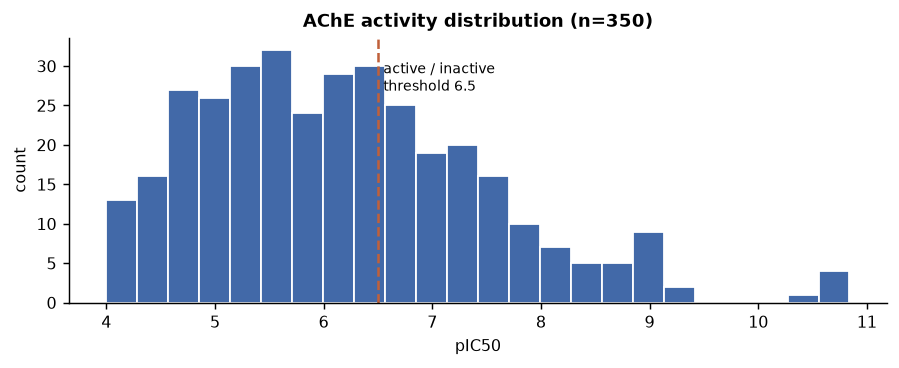

In [14]:
# Parse, confirm cleanliness (no duplicates, all valid), and look at the activity distribution.
mols = [Chem.MolFromSmiles(s) for s in raw.smiles]
assert all(m is not None for m in mols), "a SMILES failed to parse"
keys = [Chem.MolToInchiKey(m) for m in mols]
print("valid molecules: %d | unique InChIKeys: %d | duplicates: %d"
      % (len(mols), len(set(keys)), len(keys) - len(set(keys))))
fig, ax = plt.subplots(figsize=(7.0, 2.9))
ax.hist(raw.pIC50, bins=24, color="#4269a8", edgecolor="white")
ax.axvline(6.5, color="#c0603a", ls="--", lw=1.4); ax.text(6.55, ax.get_ylim()[1]*0.8, "active / inactive\nthreshold 6.5", fontsize=8)
ax.set_xlabel("pIC50"); ax.set_ylabel("count"); ax.set_title("AChE activity distribution (n=%d)" % len(raw))
print("fraction active at pIC50 >= 6.5: %.2f" % (raw.pIC50 >= 6.5).mean())
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> The pIC50 distribution of the 350 curated AChE inhibitors spans roughly four to eleven, centred near the mid-6s. There are no duplicate InChIKeys and every SMILES parses — the curation did its job. We will model the task as binary classification, "potent" (pIC50 &ge; 6.5) versus "weak", with the threshold marked; about a third of the set is active, so the classes are imbalanced and we must heed §4.5 and avoid raw accuracy. A classification framing is honest here because the measurements come from many assays and small pIC50 differences are not reliable, so a coarse potent/weak call is more defensible than a regression to two decimals.</p>

### 5.3 Representation (Unit 5)

We turn each molecule into a vector with **Morgan (ECFP4) fingerprints** — 2048-bit circular fingerprints that record which atom-centred substructures are present (Unit 5).<sup class="c"><a href="#r7">[7]</a></sup> They are the standard ligand-based representation and a strong baseline across benchmarks.<sup class="c"><a href="#r28">[28]</a></sup> We also compute a few interpretable physicochemical descriptors for the chemical-space view.

In [15]:
# ECFP4 (Morgan, radius 2) fingerprints as the model input; a few descriptors for interpretation.
gen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
def ecfp(m):
    a = np.zeros((2048,), dtype=np.int8); DataStructs.ConvertToNumpyArray(gen.GetFingerprint(m), a); return a
X = np.array([ecfp(m) for m in mols])
y = (raw.pIC50.values >= 6.5).astype(int)
desc = pd.DataFrame({"MW": [Descriptors.MolWt(m) for m in mols],
                     "logP": [Crippen.MolLogP(m) for m in mols],
                     "TPSA": [Descriptors.TPSA(m) for m in mols],
                     "HBD": [Descriptors.NumHDonors(m) for m in mols]})
print("fingerprint matrix:", X.shape, "| mean bits set per molecule: %.1f" % X.sum(1).mean())
print("class balance: %d active / %d inactive" % (y.sum(), len(y) - y.sum()))
desc.describe().round(1).loc[["mean", "min", "max"]]

fingerprint matrix: (350, 2048) | mean bits set per molecule: 47.6
class balance: 131 active / 219 inactive


,MW,logP,TPSA,HBD
mean,390.4,4.4,58.1,1.0
min,172.2,-0.9,3.2,0.0
max,593.6,10.3,182.8,5.0


Each molecule is now a 2048-dimensional sparse bit vector (only a few dozen bits set, as the printout shows) plus a handful of descriptors. This is the "turn a molecule into a vector" step of Unit 5, and from here the problem is ordinary supervised learning — with the chemistry-specific caveats of §4 attached.

### 5.4 Chemical space (Unit 8)

Before modelling, look at the data. A principal-component projection (Unit 8) of the fingerprints shows how the molecules are distributed and whether activity is cleanly separable or interleaved — a first, visual read on how hard the task is and where cliffs might lurk.

PC1+PC2 capture 11% of the fingerprint variance


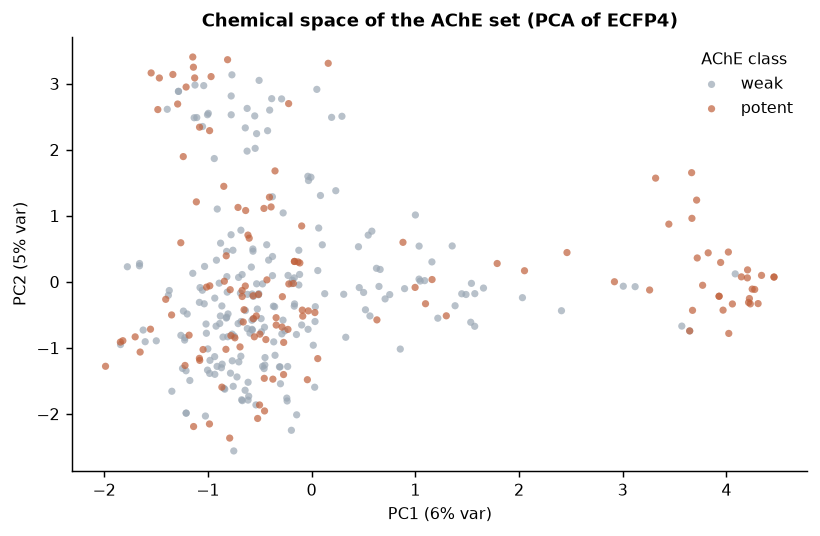

In [16]:
# PCA of the fingerprints (Unit 8), coloured by activity class: a first look at the chemical space.
from sklearn.decomposition import PCA
P = PCA(n_components=2, random_state=SEED).fit(X)
Z = P.transform(X)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for cls, col, lab in [(0, "#9aa7b4", "weak"), (1, "#c0603a", "potent")]:
    ax.scatter(Z[y == cls, 0], Z[y == cls, 1], s=16, c=col, alpha=0.7, label=lab, edgecolors="none")
ax.set_xlabel("PC1 (%.0f%% var)" % (100*P.explained_variance_ratio_[0]))
ax.set_ylabel("PC2 (%.0f%% var)" % (100*P.explained_variance_ratio_[1]))
ax.legend(frameon=False, title="AChE class"); ax.set_title("Chemical space of the AChE set (PCA of ECFP4)")
print("PC1+PC2 capture %.0f%% of the fingerprint variance" % (100*P.explained_variance_ratio_[:2].sum()))
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> The AChE molecules projected onto their first two fingerprint principal components, coloured by class. The two classes are broadly interleaved rather than cleanly separated, and the first two components capture only a small fraction of the variance — both signs that this is a genuinely hard task on diverse chemistry, not a toy that will yield a near-perfect model. Note too that potent and weak molecules sit close together in several places: those are the activity cliffs of §4.4, visible as mixed-colour neighbourhoods. The honest expectation set by this picture is a model with modest, real skill — not a spectacular one.</p>

### 5.5 Modelling (Units 12-13)

We train a **random forest** classifier<sup class="c"><a href="#r8">[8]</a></sup> on the fingerprints (Unit 13), with a fixed seed, and compare it to two baselines a result must beat to mean anything: a majority-class predictor and a simple logistic-regression-style linear model. First the optimistic view — a random-split cross-validation — which we already know (from §4.2) to expect to be too high.

In [17]:
# Random forest vs baselines, random-split 5-fold CV (ROC-AUC). This is the OPTIMISTIC estimate.
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {"majority baseline": DummyClassifier(strategy="most_frequent"),
          "logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
          "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)}
for name, mdl in models.items():
    pr = cross_val_predict(mdl, X, y, cv=skf, method="predict_proba")[:, 1]
    print("%-20s random-split CV ROC-AUC = %.3f" % (name, roc_auc_score(y, pr)))

majority baseline    random-split CV ROC-AUC = 0.500
logistic regression  random-split CV ROC-AUC = 0.789
random forest        random-split CV ROC-AUC = 0.787


Both the random forest and the linear model clearly beat the majority baseline (which is 0.50 by construction), reaching a ROC-AUC in the high 0.7s. Notably they are essentially tied here — a useful reminder that a simple linear model is a baseline worth taking seriously, and that reaching for a random forest does not automatically buy accuracy. But §4.2 warns that <em>both</em> of these random-split numbers are optimistic, because a random split leaks scaffold-neighbours into training. The honest estimate requires a scaffold split.

### 5.6 Honest validation (Unit 14): scaffold split and the optimism gap

In [18]:
# Scaffold split (Unit 11/14): whole Murcko scaffolds held out. This is the HONEST estimate.
from collections import defaultdict
def murcko(m):
    s = MurckoScaffold.GetScaffoldForMol(m); return Chem.MolToSmiles(s) if s.GetNumAtoms() else "acyclic"
scaffs = [murcko(m) for m in mols]
groups = defaultdict(list)
for i, s in enumerate(scaffs): groups[s].append(i)
test_idx, train_idx = [], []
for grp_idx in sorted(groups.values(), key=len, reverse=True):          # largest scaffolds first
    (test_idx if len(test_idx) < 0.25 * len(y) else train_idx).extend(grp_idx)
train_idx, test_idx = np.array(sorted(train_idx)), np.array(sorted(test_idx))
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X[train_idx], y[train_idx])
proba = rf.predict_proba(X[test_idx])[:, 1]
auc_scaf = roc_auc_score(y[test_idx], proba)
auc_rand = roc_auc_score(y, cross_val_predict(models["random forest"], X, y, cv=skf, method="predict_proba")[:, 1])
print("unique scaffolds: %d among %d molecules" % (len(groups), len(y)))
print("train/test sizes: %d / %d" % (len(train_idx), len(test_idx)))
print("random-split CV ROC-AUC  = %.3f  (optimistic)" % auc_rand)
print("scaffold-split ROC-AUC   = %.3f  (honest)     -> optimism gap = %.3f" % (auc_scaf, auc_rand - auc_scaf))

unique scaffolds: 273 among 350 molecules
train/test sizes: 261 / 89
random-split CV ROC-AUC  = 0.787  (optimistic)
scaffold-split ROC-AUC   = 0.680  (honest)     -> optimism gap = 0.107


A **scaffold** is the ring-system core of a molecule once its side chains are stripped — the Bemis-Murcko framework (Unit 11),<sup class="c"><a href="#r15">[15]</a></sup> and holding whole scaffolds out of training is the split best-practice QSAR guidance recommends for a realistic estimate.<sup class="c"><a href="#r11">[11]</a></sup> There is the optimism gap of Figure 1, now measured on real data: the scaffold-split ROC-AUC is materially lower than the random-split one, because most of these 350 molecules carry a distinct scaffold and predicting activity for a wholly unseen chemotype is genuinely hard. The scaffold number — not the random one — is what we report and what a model card must quote. Before trusting even that, run the y-randomization control of §4.3 on this model and data.

In [19]:
# y-randomization on the real capstone model: the real scaffold-split AUC must beat scrambled labels.
rs = np.random.RandomState(SEED)
scr_auc = []
for _ in range(25):
    yp = rs.permutation(y)
    rf_s = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1).fit(X[train_idx], yp[train_idx])
    scr_auc.append(roc_auc_score(yp[test_idx], rf_s.predict_proba(X[test_idx])[:, 1]))
scr_auc = np.array(scr_auc)
print("real scaffold AUC %.3f | scrambled AUC mean %.3f max %.3f" % (auc_scaf, scr_auc.mean(), scr_auc.max()))
print("real score exceeds all %d scrambles:" % len(scr_auc), bool(auc_scaf > scr_auc.max()))

real scaffold AUC 0.680 | scrambled AUC mean 0.503 max 0.665
real score exceeds all 25 scrambles: True


The real scaffold-split ROC-AUC sits above the scrambled distribution (whose mean is near the 0.50 of chance), so the modest skill is real, not an artefact — the model passes the chance-correlation control. We now have an honest, controlled performance estimate. The next step turns the probabilities into a decision and reads the honest classification metrics, which we first trace by hand.

### 5.7 Worked example by hand: a confusion matrix and its metrics

At a decision threshold of 0.5 the model's predictions on the scaffold-test set form a **confusion matrix**: counts of true positives (TP), false positives (FP), true negatives (TN) and false negatives (FN). From these four numbers every classification metric follows. Let us compute them by hand for a small, explicit sub-table and confirm with scikit-learn. Suppose on four held-out molecules the (truth, predicted) pairs are: (active, active), (active, inactive), (inactive, inactive), (inactive, active). Then by hand:

<div class="eq">
TP = 1 &nbsp; FN = 1 &nbsp; TN = 1 &nbsp; FP = 1<br>
precision = TP/(TP+FP) = 1/2 = 0.50 &nbsp;&nbsp; recall = TP/(TP+FN) = 1/2 = 0.50<br>
F1 = 2&middot;precision&middot;recall/(precision+recall) = 0.50 &nbsp;&nbsp;
MCC = (TP&middot;TN &minus; FP&middot;FN)/&radic;((TP+FP)(TP+FN)(TN+FP)(TN+FN)) = (1&minus;1)/&radic;(2&middot;2&middot;2&middot;2) = 0.00
</div>

So this toy classifier has 0.5 precision and recall but an MCC of exactly 0 — it is no better than chance, which the MCC reports and the 50% precision hides. The cell confirms the hand arithmetic, then prints the full confusion matrix and metrics for the real scaffold-test predictions.

toy: precision 0.50 recall 0.50 F1 0.50 MCC 0.00  (matches the hand trace)
scaffold test: balanced-acc 0.61  MCC 0.26  recall(potent) 0.35  precision(potent) 0.65


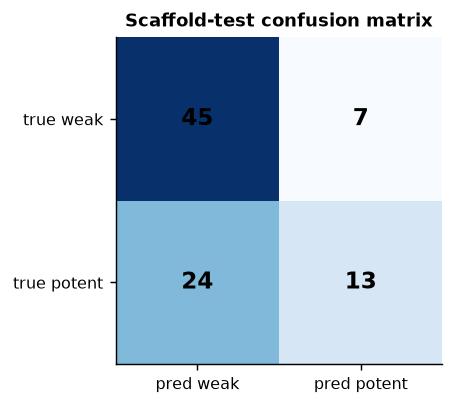

In [20]:
# Confirm the hand-traced toy metrics, then report the real scaffold-test confusion matrix and metrics.
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, matthews_corrcoef, balanced_accuracy_score
toy_true = [1, 1, 0, 0]; toy_pred = [1, 0, 0, 1]
print("toy: precision %.2f recall %.2f F1 %.2f MCC %.2f  (matches the hand trace)"
      % (precision_score(toy_true, toy_pred), recall_score(toy_true, toy_pred),
         f1_score(toy_true, toy_pred), matthews_corrcoef(toy_true, toy_pred)))
pred = (proba >= 0.5).astype(int); yt = y[test_idx]
cm = confusion_matrix(yt, pred)
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, str(v), ha="center", va="center", fontsize=13, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["pred weak", "pred potent"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["true weak", "true potent"]); ax.set_title("Scaffold-test confusion matrix")
print("scaffold test: balanced-acc %.2f  MCC %.2f  recall(potent) %.2f  precision(potent) %.2f"
      % (balanced_accuracy_score(yt, pred), matthews_corrcoef(yt, pred), recall_score(yt, pred), precision_score(yt, pred)))
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> The confusion matrix on the scaffold-held-out test set. The toy metrics printed above reproduce the hand trace exactly (precision, recall and F1 of 0.50, MCC of 0.00), confirming the formulae. On the real data the MCC and balanced accuracy are modest and positive — honest skill above chance, consistent with the ROC-AUC and the interleaved chemical space of Figure 8. The matrix also shows the error structure: the model recovers only a fraction of the potent molecules in unseen scaffolds, which is exactly the limitation the applicability domain and the model card must state plainly.</p>

### 5.8 Applicability domain (Unit 14): where may the model be believed?

A model is only reliable for molecules resembling those it was trained on — its **applicability domain** (AD, Unit 14). A simple, defensible AD for a fingerprint model is the Tanimoto similarity to the nearest training molecule: predictions for test molecules far from all training molecules should be trusted less. To see this relationship we need test molecules spanning a wide range of similarity to the training set; the scaffold split of §5.6 deliberately removed the similar ones, so for this illustration only we use a random-split holdout, whose test molecules run from near-duplicates to quite dissimilar. The relationship we extract — error grows as similarity to the training set falls — is general and applies to the scaffold model too.

NN-Tanimoto to training spans 0.15-1.00; corr(similarity, error) = -0.19 (negative = AD works)
  low   third: mean NN 0.32  accuracy 0.71  mean soft-error 0.37
  mid   third: mean NN 0.55  accuracy 0.74  mean soft-error 0.35
  high  third: mean NN 0.79  accuracy 0.80  mean soft-error 0.28


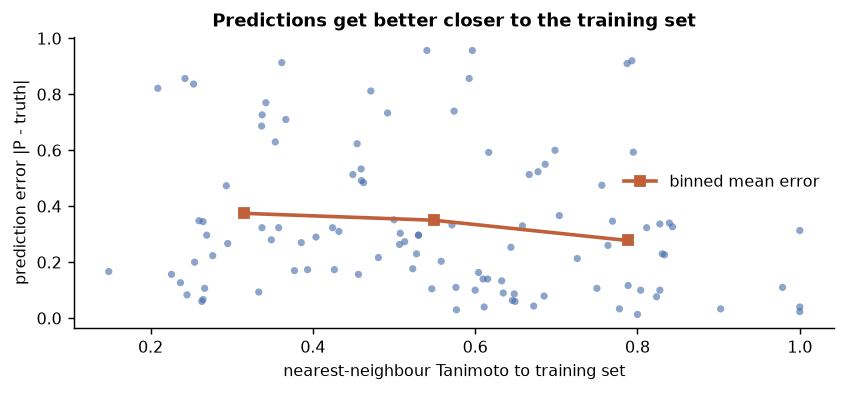

In [21]:
# AD illustration needs test molecules spanning a WIDE similarity range, so we use a random-split holdout
# here (the scaffold split deliberately removed the similar ones). The relationship is what we are after.
from sklearn.model_selection import train_test_split
tr_i, te_i = train_test_split(np.arange(len(y)), test_size=0.3, random_state=SEED, stratify=y)
rf_ad = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X[tr_i], y[tr_i])
pr_ad = rf_ad.predict_proba(X[te_i])[:, 1]; yt_ad = y[te_i]
tr_fps = [gen.GetFingerprint(mols[i]) for i in tr_i]
nn_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(gen.GetFingerprint(mols[i]), tr_fps)) for i in te_i])
soft_err = np.abs(pr_ad - yt_ad)                            # soft (Brier-style) error per molecule
print("NN-Tanimoto to training spans %.2f-%.2f; corr(similarity, error) = %.2f (negative = AD works)"
      % (nn_sim.min(), nn_sim.max(), np.corrcoef(nn_sim, soft_err)[0, 1]))
pred_ad = (pr_ad >= 0.5).astype(int)
order = np.argsort(nn_sim); thirds = np.array_split(order, 3)
for lab, t in zip(["low", "mid", "high"], thirds):
    acc = (pred_ad[t] == yt_ad[t]).mean()
    print("  %-5s third: mean NN %.2f  accuracy %.2f  mean soft-error %.2f" % (lab, nn_sim[t].mean(), acc, soft_err[t].mean()))
fig, ax = plt.subplots(figsize=(6.6, 3.1))
ax.scatter(nn_sim, soft_err, s=16, c="#4269a8", alpha=0.6, edgecolors="none")
ax.plot([nn_sim[t].mean() for t in thirds], [soft_err[t].mean() for t in thirds], "s-", color="#c0603a", lw=2, label="binned mean error")
ax.set_xlabel("nearest-neighbour Tanimoto to training set"); ax.set_ylabel("prediction error |P - truth|")
ax.set_title("Predictions get better closer to the training set"); ax.legend(frameon=False)
fig.tight_layout()

<p class="caption"><b>Figure 10.</b> Each held-out molecule's prediction error (the gap between the predicted probability and the truth) against its nearest-neighbour Tanimoto similarity to the training set; the red line joins the mean error in three similarity bins. The error falls as similarity rises — the correlation is negative and the high-similarity third is both more accurate and lower-error than the low-similarity third, as the printout shows. This is the operational meaning of an applicability domain: the model may report a prediction for any molecule, but it is only entitled to be <em>believed</em> for molecules close enough to what it has seen. The trend is real but noisy on a few hundred molecules, which is itself the honest message — an AD is a soft warning, not a hard guarantee. A prediction reported without an AD flag is an incomplete result.</p>

### 5.9 A small design exercise (Units 17-18), honestly filtered

Finally, the forward step: propose new molecules and score them — but honestly. We enumerate a tiny analogue series with a reaction SMARTS (Unit 17): an amide coupling of one carboxylic acid with several amines. Each product is scored by the model, then subjected to the honesty filters built above — is it inside the applicability domain, and is it synthetically accessible (a synthetic-accessibility score, Unit 17)?<sup class="c"><a href="#r19">[19]</a></sup> In a fuller workflow the same products would also pass drug-likeness gates such as the quantitative estimate of drug-likeness, QED (Unit 9),<sup class="c"><a href="#r23">[23]</a></sup> before any are considered; here we keep the filters to the two that bear directly on honesty — the applicability domain and synthesizability. The point is not to "discover" an inhibitor from 350 training molecules; it is to produce an honest shortlist. As we will see, the model predicts none of this small series to be potent, and several of the analogues fall outside the applicability domain where even that prediction is unreliable — an informative, cautious result, reported rather than hidden.

In [22]:
# Enumerate amide analogues (reaction SMARTS, Unit 17), score them, and apply the honesty filters.
import os, sys
from rdkit.Chem import RDConfig
sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score")); import sascorer   # RDKit synthetic-accessibility
rxn = AllChem.ReactionFromSmarts("[C:1](=O)[OX2H1].[N!$(N=*):2]>>[C:1](=O)[N:2]")   # amide coupling
acid = Chem.MolFromSmiles("O=C(O)c1ccc(Cl)cc1")                                     # one fixed aryl acid
amines = ["NCc1ccccc1", "NCCc1ccncc1", "NC1CCN(C)CC1", "Nc1ccc(F)cc1", "NCCN1CCOCC1",
          "NC1CCCCC1", "Nc1ccc(C(=O)O)cc1", "NCC(F)(F)F", "NC1CC2CCC1C2", "NCCc1c[nH]c2ccccc12"]
prods = []
for am in amines:
    for p in rxn.RunReactants((acid, Chem.MolFromSmiles(am))):
        pm = p[0]; Chem.SanitizeMol(pm); prods.append(pm); break
scaf_fps = [gen.GetFingerprint(mols[i]) for i in train_idx]      # AD = similarity to the deployed model's training set
Xp = np.array([ecfp(m) for m in prods])
pp = rf.predict_proba(Xp)[:, 1]
ad = np.array([max(DataStructs.BulkTanimotoSimilarity(gen.GetFingerprint(m), scaf_fps)) for m in prods])
sa = np.array([sascorer.calculateScore(m) for m in prods])
res = pd.DataFrame({"P(potent)": pp.round(2), "NN_Tanimoto": ad.round(2), "SA_score": sa.round(1),
                    "in_AD": ad >= 0.3, "easy_synth": sa <= 4.0})
print(res.to_string())
print("\nenumerated %d analogues; predicted potent (P>=0.5): %d; inside AD: %d; inside AD AND easy to make: %d"
      % (len(prods), int((res["P(potent)"] >= 0.5).sum()), int(res.in_AD.sum()), int((res.in_AD & res.easy_synth).sum())))

   P(potent)  NN_Tanimoto  SA_score  in_AD  easy_synth
0       0.12         0.38       1.2   True        True
1       0.22         0.32       1.6   True        True
2       0.12         0.32       1.7   True        True
3       0.10         0.29       1.3  False        True
4       0.15         0.44       1.7   True        True
5       0.12         0.29       1.5  False        True
6       0.16         0.31       1.4   True        True
7       0.12         0.29       1.7  False        True
8       0.22         0.26       3.5  False        True
9       0.15         0.40       1.7   True        True

enumerated 10 analogues; predicted potent (P>=0.5): 0; inside AD: 6; inside AD AND easy to make: 6


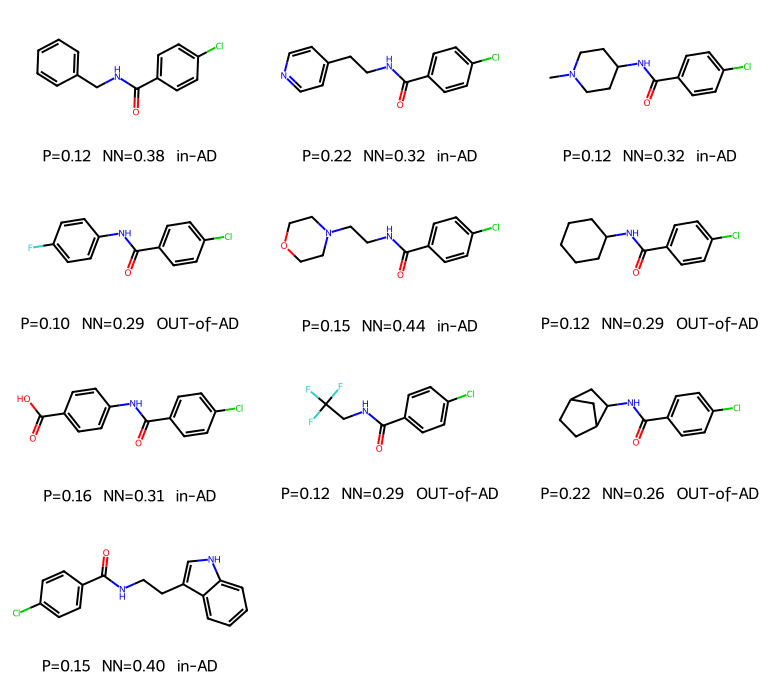

In [23]:
# Draw the enumerated analogues with their honest scores as legends.
legends = ["P=%.2f  NN=%.2f  %s" % (p, a, "in-AD" if a >= 0.3 else "OUT-of-AD") for p, a in zip(pp, ad)]
Draw.MolsToGridImage(prods, molsPerRow=3, subImgSize=(260, 170), legends=legends)

<p class="caption"><b>Figure 11.</b> Ten enumerated amide analogues, each annotated with the model's predicted probability of being potent and its nearest-neighbour Tanimoto to the training set (with the applicability-domain verdict). The honest reading is deliberately sobering: the model emits a probability for every one, but it predicts none to be potent, and only the in-AD members carry any warranted confidence — the out-of-AD ones (marked OUT) should not be scored at all. A design exercise that reported only the predicted probabilities, ignoring the AD, would be precisely the self-deception §4 warns against. The deliverable is not "these are active" but "the model, honestly used, flags none of these as worth pursuing, and cannot even comment on several of them."</p>

### 5.10 The data sheet and model card

The project ends in two documents that make it honest for others, following the "datasheets for datasets"<sup class="c"><a href="#r18">[18]</a></sup> and "model cards"<sup class="c"><a href="#r17">[17]</a></sup> templates adapted to cheminformatics. They state provenance, intended use, performance under honest validation, and — most importantly — the limits.

<div class="box key"><h4>Data sheet — AChE inhibitor snapshot</h4>
<ul>
<li><b>Source &amp; provenance:</b> acetylcholinesterase (ChEMBL target CHEMBL220), IC50 activities from ChEMBL,<sup class="c"><a href="#r16">[16]</a></sup> frozen as a versioned snapshot (content hash printed in §5.1).</li>
<li><b>Size &amp; composition:</b> 350 unique molecules (deduplicated on InChIKey), pIC50 ~4-11; ~1/3 labelled potent at the 6.5 threshold.</li>
<li><b>Curation:</b> largest-fragment desalting, charge neutralisation, duplicate aggregation by median pIC50 (Units 4, 7); molecular-weight window 150-600.</li>
<li><b>Known limitations:</b> IC50 values pooled across heterogeneous assays; high scaffold diversity; activity cliffs present (Figure 8). Not a benchmark of record — a teaching snapshot.</li>
<li><b>Licence/use:</b> ChEMBL is released under CC BY-SA; this derived snapshot is for teaching.</li>
</ul></div>

<div class="box key"><h4>Model card — AChE potent/weak classifier</h4>
<ul>
<li><b>Model:</b> random forest (300 trees, seed 0)<sup class="c"><a href="#r8">[8]</a></sup> on 2048-bit ECFP4 fingerprints<sup class="c"><a href="#r7">[7]</a></sup>; scikit-learn.<sup class="c"><a href="#r25">[25]</a></sup></li>
<li><b>Intended use:</b> rank-order candidate molecules for AChE potency <em>within the applicability domain</em>, as a triage aid — not a replacement for assay.</li>
<li><b>Honest performance:</b> scaffold-split ROC-AUC (reported, not the higher random-split value); modest positive MCC and balanced accuracy; passes a 25x y-randomization control.</li>
<li><b>Applicability domain:</b> nearest-neighbour Tanimoto &ge; 0.3 to the training set; predictions outside it are unreliable (Figure 10) and must be flagged.</li>
<li><b>Out of scope / limitations:</b> novel scaffolds, activity cliffs, selectivity, ADMET, and any quantitative pIC50 claim. The model predicts a coarse potent/weak class on known chemotypes only.</li>
<li><b>Ethical/scientific note:</b> intended to reduce, not replace, experiments; a model that is honest about its limits is more useful than one that overstates them.<sup class="c"><a href="#r27">[27]</a></sup></li>
</ul></div>

A result delivered with this data sheet and model card is one another scientist can evaluate, reproduce and either trust or reject on stated grounds. That is the difference between a demonstration and a credible contribution — the whole point of this unit and a fitting close to the course.<sup class="c"><a href="#r14">[14]</a></sup><sup class="c"><a href="#r21">[21]</a></sup>

## 6. Summary

You should now be able to explain, without notes:

- Why a cheminformatics result is only as good as its reproducibility and honesty, and what the "optimism gap" between a random-split and an honest-split score is.
- How to make a project reproducible: pin versions, fix seeds (or report spread over seeds), and version the data with a content hash and a frozen snapshot.
- The FAIR principles and their cheminformatics reading, with the InChIKey as the universal molecular identifier.
- The five classic failure modes — overfitting, optimistic splits/leakage, chance correlation, activity cliffs, and the wrong metric on imbalanced data — and the control for each.
- The full end-to-end pipeline on real data: acquisition, curation, representation, chemical-space view, modelling, scaffold-split validation, y-randomization control, a hand-checked confusion matrix, an applicability domain, an honestly-filtered design step, and a data sheet plus model card.
- Why the scaffold-split score, the AD flag and the limitations section — not the headline accuracy — are what a credible report quotes.

## 7. Self-assessment

<details><summary>1. A colleague reports a random-forest QSAR model with a cross-validated R&sup2; of 0.85 from a random 80/20 split. What is the first question to ask?</summary>How was the data split? A random split on molecular data usually leaks scaffold-neighbours of the test molecules into training, inflating the score (§4.2, Figure 4). Ask for the scaffold-split or time-split estimate; the honest number is typically much lower, and that is the one that predicts performance on new chemistry.</details>

<details><summary>2. Why does fixing <code>random_state</code> make a model reproducible but not necessarily correct?</summary>The seed makes the pseudo-random draws (bootstrap samples, feature subsets, shuffles) identical across runs, so the <em>reported</em> run reproduces. It does nothing about whether the split leaks, the metric flatters, or the model generalises. Reproducible and honest are independent properties; you need both.</details>

<details><summary>3. You permute (scramble) the activity labels, retrain, and still get a cross-validated R&sup2; of 0.4. What does this tell you?</summary>That the pipeline is broken: with the structure-activity relationship destroyed, an honest procedure should score near zero (§4.3, Figure 5). A high score on scrambled labels means the apparent skill is an artefact — too many features, leakage from the split, or a flawed metric — not real learning.</details>

<details><summary>4. On a dataset that is 5% active, a classifier posts 95% accuracy. Is it good?</summary>Unknown from accuracy alone — a predict-everything-inactive model also scores 95% (§4.5). Report balanced accuracy, MCC or ROC-AUC, which are not fooled by class imbalance. The trivial model scores 0.50 balanced accuracy and 0.00 MCC, exposing it.</details>

<details><summary>5. What is an activity cliff and why does it limit a fingerprint model?</summary>A pair of structurally very similar molecules (high Tanimoto) with very different activity (§4.4, Figure 6). Fingerprint models interpolate between near-neighbours, so near a cliff they predict two very different molecules to be similar in activity and are necessarily wrong for at least one. Cliffs are where average accuracy hides large errors.</details>

<details><summary>6. Why does this unit freeze a data snapshot and store its content hash instead of downloading live each run?</summary>Public databases change, so a live download is not reproducible — the rows differ over time (§2). A frozen, canonicalised snapshot with a SHA-256 content hash makes the dataset a fixed, verifiable object; anyone can confirm they hold the same data and obtain the same numbers. The hash is order-independent but changes if any value is edited.</details>

<details><summary>7. What does "Findable" in FAIR mean for a molecule, concretely?</summary>That the molecule has a persistent, globally unique, structure-derived identifier — the InChIKey — plus a database accession (ChEMBL/PubChem ID). Because the InChIKey is computed from structure, two labs independently drawing the same molecule get the same key, making it the safe primary key for merging datasets (§3).</details>

<details><summary>8. In the capstone, the random-split ROC-AUC is in the high 0.7s but the scaffold-split ROC-AUC is noticeably lower. Which do you put in the model card, and why?</summary>The scaffold-split value. It estimates performance on unseen chemotypes — the situation the model will actually face — whereas the random-split value is inflated by scaffold leakage (§5.6). Reporting the higher number would be the optimism of Figure 1.</details>

<details><summary>9. Trace by hand: a classifier gives TP=8, FP=2, TN=5, FN=5. Compute precision, recall and accuracy.</summary>precision = TP/(TP+FP) = 8/10 = 0.80; recall = TP/(TP+FN) = 8/13 &asymp; 0.62; accuracy = (TP+TN)/total = 13/20 = 0.65. The gap between precision and recall shows the model is conservative about calling "active" — it misses several actives (FN=5) while making few false alarms (FP=2).</details>

<details><summary>10. What is an applicability domain and how is a simple one defined for a fingerprint model?</summary>The region of chemical space where the model's predictions are reliable (§5.8). A simple AD is the nearest-neighbour Tanimoto similarity to the training set: a test molecule below a cutoff (e.g. 0.3) is too dissimilar to any training molecule for the prediction to be trusted. Predictions outside the AD must be flagged, not hidden.</details>

<details><summary>11. In the design exercise most enumerated analogues fell outside the applicability domain. Is that a failure?</summary>No — it is the honest, informative outcome. It says the model (trained on 350 specific molecules) cannot be trusted to score those novel structures, so it should not be used to prioritise them. Reporting that is exactly the discipline the unit teaches; hiding it and quoting the predicted probabilities would be self-deception (§5.9).</details>

<details><summary>12. Why does a credible cheminformatics report need a model card and a data sheet, not just a performance number?</summary>Because the number is meaningless without its provenance, the split that produced it, the metric, the applicability domain and the stated limits. The data sheet and model card (§5.10) record all of these so another scientist can reproduce, evaluate and appropriately trust or reject the result. A number alone invites the reader to over-trust it.</details>

## Glossary

<dl class="gloss">
<dt>Applicability domain (AD)</dt><dd>The region of chemical space where a model's predictions are reliable; here, molecules within a nearest-neighbour Tanimoto cutoff of the training set.</dd>
<dt>Assay</dt><dd>A laboratory experiment measuring a molecule's effect on a biological target; the source of the activity values a QSAR model predicts.</dd>
<dt>Activity cliff</dt><dd>A pair of structurally very similar molecules with markedly different activity; a local failure of the similarity principle.</dd>
<dt>Confusion matrix</dt><dd>The 2x2 table of true/false positives and negatives from which precision, recall, F1 and MCC are computed.</dd>
<dt>Data versioning</dt><dd>Fixing and identifying the exact dataset used (a frozen snapshot plus a content hash) so a result is reproducible.</dd>
<dt>FAIR</dt><dd>Findable, Accessible, Interoperable, Reusable — principles for scientific data management and stewardship.</dd>
<dt>IC50 / pIC50</dt><dd>The concentration that halves a target's activity; pIC50 = &minus;log<sub>10</sub>(IC50 in M), higher meaning more potent.</dd>
<dt>InChIKey</dt><dd>A 27-character hash of a molecule's canonical InChI; a persistent, structure-derived unique identifier.</dd>
<dt>Matthews correlation coefficient (MCC)</dt><dd>A balanced classification metric using all four confusion-matrix counts; 0 means chance, 1 perfect.</dd>
<dt>Model card</dt><dd>A short structured document stating a model's intended use, honest performance, applicability domain and limitations.</dd>
<dt>Overfitting</dt><dd>Fitting the training data (including its noise) so closely that performance on new data is poor.</dd>
<dt>Random forest</dt><dd>An ensemble of decision trees trained on bootstrap samples with random feature subsets; a strong default model.</dd>
<dt>ROC-AUC</dt><dd>Area under the receiver-operating-characteristic curve; the probability a random active is ranked above a random inactive.</dd>
<dt>Scaffold split</dt><dd>A data split that holds out whole molecular scaffolds, estimating performance on genuinely new chemotypes.</dd>
<dt>y-randomization</dt><dd>Scrambling the labels and retraining to check that a model's apparent skill is not chance correlation.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Walters WP, Barzilay R. Applications of deep learning in molecule generation and molecular property prediction. <em>Acc Chem Res</em>. 2021;54(2):263-270. <a href="https://doi.org/10.1021/acs.accounts.0c00699">doi:10.1021/acs.accounts.0c00699</a></li>
<li id="r2">Bender A, Cortés-Ciriano I. Artificial intelligence in drug discovery: what is realistic, what are illusions? Part 1: ways to make an impact, and why we are not there yet. <em>Drug Discov Today</em>. 2021;26(2):511-524. <a href="https://doi.org/10.1016/j.drudis.2020.12.009">doi:10.1016/j.drudis.2020.12.009</a></li>
<li id="r3">Bender A, Cortés-Ciriano I. Artificial intelligence in drug discovery: what is realistic, what are illusions? Part 2: a discussion of chemical and biological data. <em>Drug Discov Today</em>. 2021;26(4):1040-1052. <a href="https://doi.org/10.1016/j.drudis.2020.11.037">doi:10.1016/j.drudis.2020.11.037</a></li>
<li id="r4">Artrith N, Butler KT, Coudert F-X, Han S, Isayev O, Jain A, Walsh A. Best practices in machine learning for chemistry. <em>Nat Chem</em>. 2021;13:505-508. <a href="https://doi.org/10.1038/s41557-021-00716-z">doi:10.1038/s41557-021-00716-z</a></li>
<li id="r5">Wilkinson MD, Dumontier M, Aalbersberg IJ, et al. The FAIR Guiding Principles for scientific data management and stewardship. <em>Sci Data</em>. 2016;3:160018. <a href="https://doi.org/10.1038/sdata.2016.18">doi:10.1038/sdata.2016.18</a></li>
<li id="r6">Landrum G. RDKit: Open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r7">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r8">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r9">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r10">Golbraikh A, Tropsha A. Beware of q2! <em>J Mol Graph Model</em>. 2002;20(4):269-276. <a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r11">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6-7):476-488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r12">Wallach I, Heifets A. Most ligand-based classification benchmarks reward memorization rather than generalization. <em>J Chem Inf Model</em>. 2018;58(5):916-932. <a href="https://doi.org/10.1021/acs.jcim.7b00403">doi:10.1021/acs.jcim.7b00403</a></li>
<li id="r13">Sieg J, Flachsenberg F, Rarey M. In need of bias control: evaluating chemical data for machine learning in structure-based virtual screening. <em>J Chem Inf Model</em>. 2019;59(3):947-961. <a href="https://doi.org/10.1021/acs.jcim.8b00712">doi:10.1021/acs.jcim.8b00712</a></li>
<li id="r14">Yang K, Swanson K, Jin W, et al. Analyzing learned molecular representations for property prediction. <em>J Chem Inf Model</em>. 2019;59(8):3370-3388. <a href="https://doi.org/10.1021/acs.jcim.9b00237">doi:10.1021/acs.jcim.9b00237</a></li>
<li id="r15">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r16">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay data. <em>Nucleic Acids Res</em>. 2019;47(D1):D930-D940. <a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r17">Mitchell M, Wu S, Zaldivar A, et al. Model cards for model reporting. <em>Proc Conf Fairness, Accountability, and Transparency (FAT*)</em>. 2019:220-229. <a href="https://doi.org/10.1145/3287560.3287596">doi:10.1145/3287560.3287596</a></li>
<li id="r18">Gebru T, Morgenstern J, Vecchione B, et al. Datasheets for datasets. <em>Commun ACM</em>. 2021;64(12):86-92. <a href="https://doi.org/10.1145/3458723">doi:10.1145/3458723</a></li>
<li id="r19">Ertl P, Schuffenhauer A. Estimation of synthetic accessibility score of drug-like molecules based on molecular complexity and fragment contributions. <em>J Cheminform</em>. 2009;1:8. <a href="https://doi.org/10.1186/1758-2946-1-8">doi:10.1186/1758-2946-1-8</a></li>
<li id="r20">van Tilborg D, Alenicheva A, Grisoni F. Exposing the limitations of molecular machine learning with activity cliffs. <em>J Chem Inf Model</em>. 2022;62(23):5938-5951. <a href="https://doi.org/10.1021/acs.jcim.2c01073">doi:10.1021/acs.jcim.2c01073</a></li>
<li id="r21">Wu Z, Ramsundar B, Feinberg EN, et al. MoleculeNet: a benchmark for molecular machine learning. <em>Chem Sci</em>. 2018;9:513-530. <a href="https://doi.org/10.1039/c7sc02664a">doi:10.1039/c7sc02664a</a></li>
<li id="r22">Lipinski CA, Lombardo F, Dominy BW, Feeney PJ. Experimental and computational approaches to estimate solubility and permeability in drug discovery and development settings. <em>Adv Drug Deliv Rev</em>. 1997;23(1-3):3-25. <a href="https://doi.org/10.1016/S0169-409X(96)00423-1">doi:10.1016/S0169-409X(96)00423-1</a></li>
<li id="r23">Bickerton GR, Paolini GV, Besnard J, Muresan S, Hopkins AL. Quantifying the chemical beauty of drugs. <em>Nat Chem</em>. 2012;4:90-98. <a href="https://doi.org/10.1038/nchem.1243">doi:10.1038/nchem.1243</a></li>
<li id="r24">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31-36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r25">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825-2830. <a href="https://jmlr.org/papers/v12/pedregosa11a.html">jmlr.org/papers/v12/pedregosa11a.html</a> (JMLR article; no DOI — stable publisher URL given)</li>
<li id="r26">Kim S, Chen J, Cheng T, et al. PubChem 2023 update. <em>Nucleic Acids Res</em>. 2023;51(D1):D1373-D1380. <a href="https://doi.org/10.1093/nar/gkac956">doi:10.1093/nar/gkac956</a></li>
<li id="r27">Jiménez-Luna J, Grisoni F, Schneider G. Drug discovery with explainable artificial intelligence. <em>Nat Mach Intell</em>. 2020;2:573-584. <a href="https://doi.org/10.1038/s42256-020-00236-4">doi:10.1038/s42256-020-00236-4</a></li>
<li id="r28">Riniker S, Landrum GA. Open-source platform to benchmark fingerprints for ligand-based virtual screening. <em>J Cheminform</em>. 2013;5:26. <a href="https://doi.org/10.1186/1758-2946-5-26">doi:10.1186/1758-2946-5-26</a></li>
<li id="r29">Hawkins DM. The problem of overfitting. <em>J Chem Inf Comput Sci</em>. 2004;44(1):1-12. <a href="https://doi.org/10.1021/ci0342472">doi:10.1021/ci0342472</a></li>
<li id="r30">Rücker C, Rücker G, Meringer M. y-Randomization and its variants in QSPR/QSAR. <em>J Chem Inf Model</em>. 2007;47(6):2345-2357. <a href="https://doi.org/10.1021/ci700157b">doi:10.1021/ci700157b</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Springer; 2007. — The field's standard text; chapters on descriptors, similarity and data analysis underpin this capstone.</li>
<li>Bajorath J (ed.). <em>Chemoinformatics for Drug Discovery</em>. Wiley; 2014. — Applications-oriented chapters on QSAR and virtual screening.</li>
<li>James G, Witten D, Hastie T, Tibshirani R. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023. — Overfitting, cross-validation and model assessment at the right level (free PDF).</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras &amp; TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Practical pipelines, metrics and validation in scikit-learn.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>Practical Cheminformatics (P. Walters) — worked, honest cheminformatics case studies: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li>TeachOpenCADD talktorials (Volkamer Lab) — end-to-end data-acquisition-to-model notebooks: <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>ChEMBL web interface and REST API documentation — <a href="https://www.ebi.ac.uk/chembl/">ebi.ac.uk/chembl</a>.</li>
<li>scikit-learn user guide, "Model evaluation" and "Cross-validation" — <a href="https://scikit-learn.org/stable/model_selection.html">scikit-learn.org</a>.</li>
<li>The Turing Way — a community handbook on reproducible research — <a href="https://the-turing-way.netlify.app/">the-turing-way.netlify.app</a>.</li>
</ul>